## model defined to be implemented

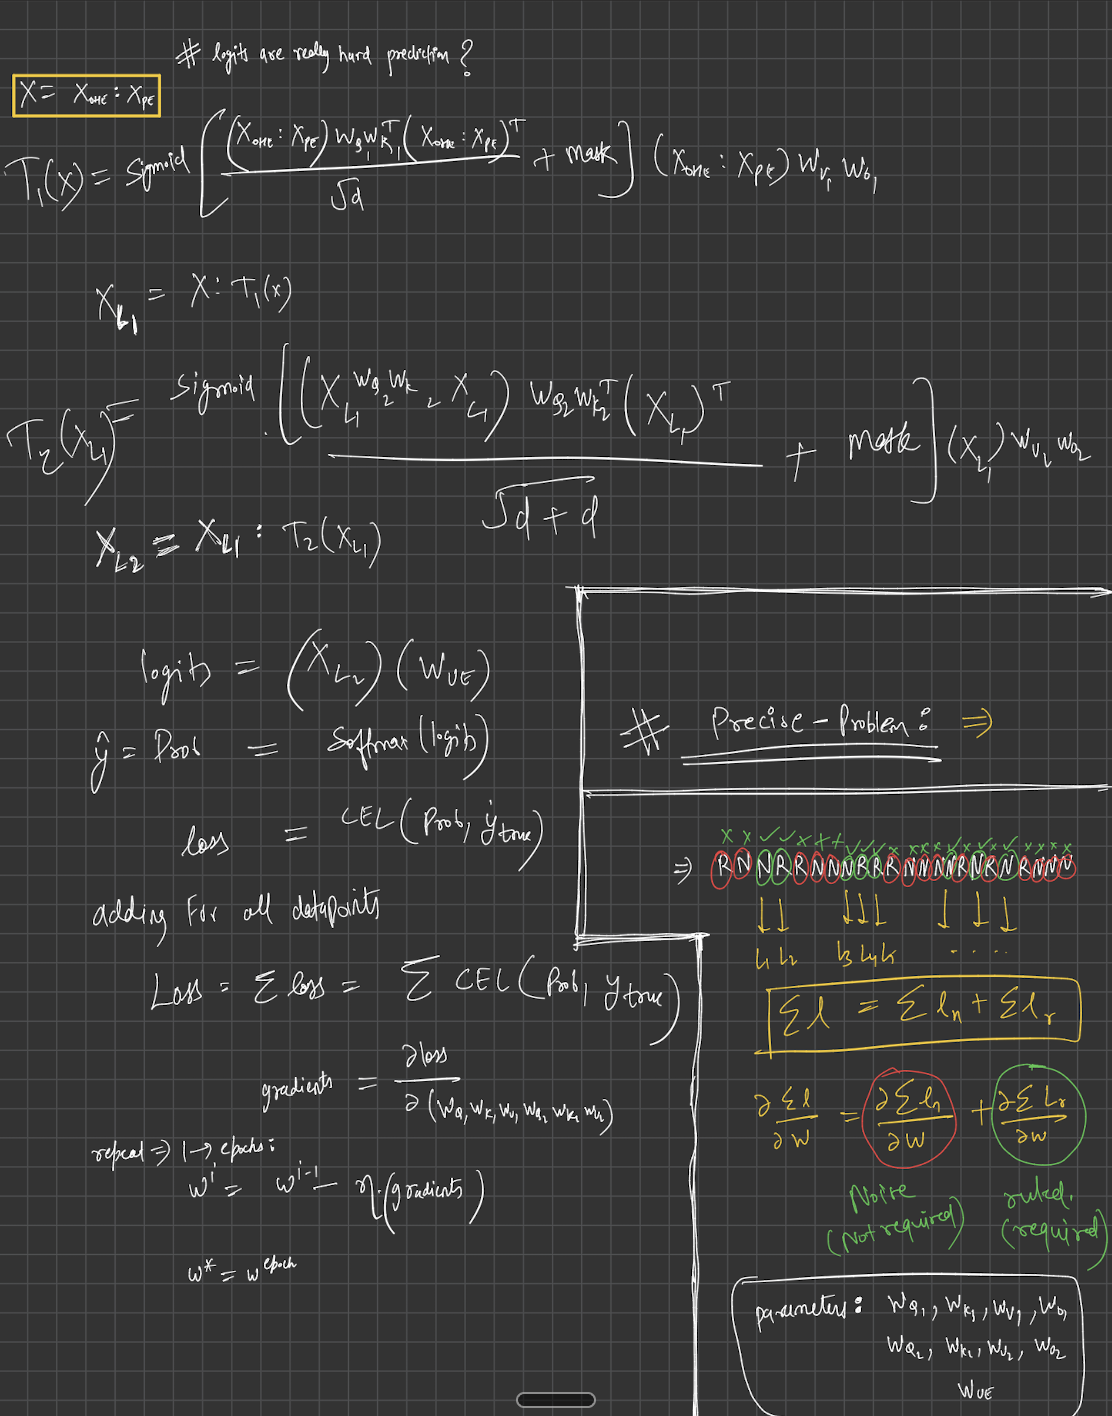

>>> Running 4-Way Accuracy Comparison on cuda:1


Evaluating x=0.9: 100%|██████████| 4/4 [00:00<00:00,  5.35it/s]


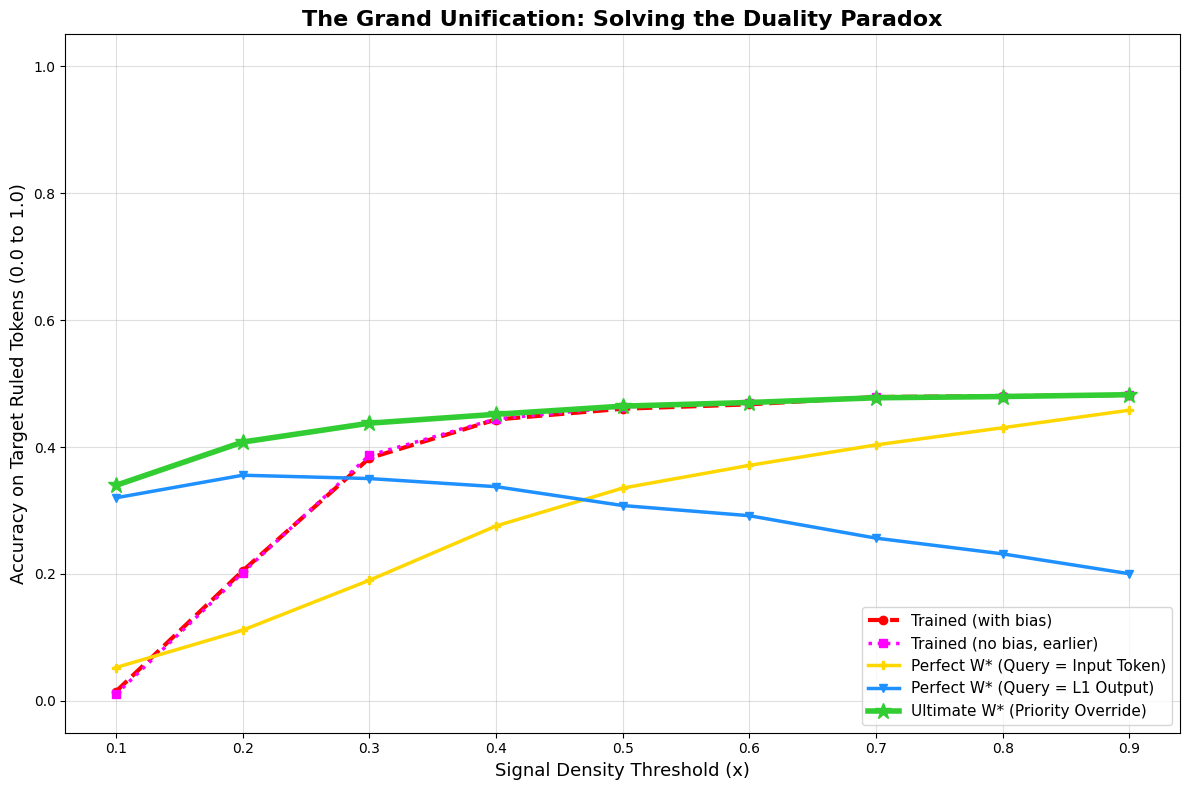

In [1]:

# Imports i'll need
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import os
from tqdm import tqdm

# --- 1. Configurations ---
CONFIG = {
    'total_vocab': 20, 
    'vocab_set1': 10,       
    'seq_len': 200,         
    'attn_dim': 64,         # this needs to be attended.
    'device': 'cuda:1' if torch.cuda.is_available() else 'cpu',  
    'artifact_dir': '/home/hariguru/ashutosh/ICL/2. trained_with_bias', 
    'output_dir': 'artifacts_bias',
    'thresholds': [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9], 
    'num_test_seqs': 1000,   # so total 1000*200 = 200000 tokens. 
    'batch_size': 250, 
    # Toggle to overlay the earlier trained model (no bias) for comparison
    'compare_earlier': True, 
    'earlier_artifact_dir': '/home/hariguru/ashutosh/expts/experiment_artifacts',
}   


# creating directory to save the outputs.
os.makedirs(CONFIG['output_dir'], exist_ok=True)


# --- 2. defining the a attention head -----
class ConcatAttentionBlock(nn.Module):

    """
    What this will do take in the input and compute the output processing that input, then 
    it'll contanate back that output in the same input passed. 
    """

    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.output_dim = output_dim
        self.W_q = nn.Linear(input_dim, output_dim, bias=False)
        self.W_k = nn.Linear(input_dim, output_dim, bias=False)
        self.W_v = nn.Linear(input_dim, output_dim, bias=False)
        self.W_o = nn.Linear(output_dim, output_dim, bias=False)

    def forward(self, x, mask=None):
        Q, K, V = self.W_q(x), self.W_k(x), self.W_v(x)
        scores = torch.bmm(Q, K.transpose(1, 2)) / (self.output_dim ** 0.5)
        if mask is not None: scores += mask
        attn_weights = F.softmax(scores, dim=-1)
        attn_out = self.W_o(torch.bmm(attn_weights, V))
        return torch.cat([x, attn_out], dim=-1), attn_weights


# bias=True in fc_out to match the trained_with_bias checkpoints
class DisentangledTransformer(nn.Module):

    """
    defing the model as per our need form the above markdown cell. which is model utilyzing concatenation block with bias 
    added in the end un-embedding layer.

    - First it's passing in, passed =  dim_pos_embed + seq_len
    - Then using the block defined it's projecting that on that to, output_l1 = passed  + config['attn_dim']
    - Similarly it's taking in this output_l1() and projecting that back to output_l2 = output_l1 + config['attn_dim']

    """

    def __init__(self):
        super().__init__()
        self.initial_dim = CONFIG['total_vocab'] + CONFIG['seq_len']
        self.layer1 = ConcatAttentionBlock(self.initial_dim, CONFIG['attn_dim'])
        self.layer2 = ConcatAttentionBlock(self.initial_dim + CONFIG['attn_dim'], CONFIG['attn_dim'])
        self.fc_out = nn.Linear(self.initial_dim + 2 * CONFIG['attn_dim'], CONFIG['total_vocab'], bias=True)

    def forward(self, x):
        B, T = x.shape
        tokens_oh = F.one_hot(x, num_classes=CONFIG['total_vocab']).float()
        pos_oh = F.one_hot(torch.arange(T, device=x.device), num_classes=CONFIG['seq_len']).float().unsqueeze(0).repeat(B, 1, 1)
        x_stream = torch.cat([tokens_oh, pos_oh], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        x_stream, a1 = self.layer1(x_stream, mask)
        x_stream, a2 = self.layer2(x_stream, mask)
        return self.fc_out(x_stream), [a1, a2]


# Earlier model (no bias) for comparison
class DisentangledTransformerNoBias(nn.Module):

    """
    model without bias

    """

    def __init__(self):
        super().__init__()
        self.initial_dim = CONFIG['total_vocab'] + CONFIG['seq_len']
        self.layer1 = ConcatAttentionBlock(self.initial_dim, CONFIG['attn_dim'])
        self.layer2 = ConcatAttentionBlock(self.initial_dim + CONFIG['attn_dim'], CONFIG['attn_dim'])
        self.fc_out = nn.Linear(self.initial_dim + 2 * CONFIG['attn_dim'], CONFIG['total_vocab'], bias=False)

    def forward(self, x):
        B, T = x.shape
        tokens_oh = F.one_hot(x, num_classes=CONFIG['total_vocab']).float()
        pos_oh = F.one_hot(torch.arange(T, device=x.device), num_classes=CONFIG['seq_len']).float().unsqueeze(0).repeat(B, 1, 1)
        x_stream = torch.cat([tokens_oh, pos_oh], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        x_stream, a1 = self.layer1(x_stream, mask)
        x_stream, a2 = self.layer2(x_stream, mask)
        return self.fc_out(x_stream), [a1, a2]
        

# The Perfect Theoretical Model (W*) - Configurable for all 3 strategies
class PerfectInductionTransformer(nn.Module):

    """
    construction of the pure model with all three stretegies. 

    """

    def __init__(self, query_type='input'):
        super().__init__()
        self.query_type = query_type
        self.initial_dim = CONFIG['total_vocab'] + CONFIG['seq_len']
        self.attn_dim = self.initial_dim  
        self.layer1 = ConcatAttentionBlock(self.initial_dim, self.attn_dim)
        self.layer2 = ConcatAttentionBlock(self.initial_dim + self.attn_dim, self.attn_dim)
        self.fc_out = nn.Linear(self.initial_dim + 2 * self.attn_dim, CONFIG['total_vocab'], bias=False)
        self._set_perfect_weights()
    
    def _set_perfect_weights(self):
        V = CONFIG['total_vocab']
        T = CONFIG['seq_len']
        D = self.attn_dim
        V_rule = CONFIG['vocab_set1']
        
        # --- LAYER 1: Strict Signal Retriever ---
        self.layer1.W_q.weight.data = torch.eye(D) * (D ** 0.5)
        Target1 = torch.zeros(D, D)
        for id_k in range(V_rule, V): Target1[id_k, :] = -1e9
        alpha = 20.0
        for t_q in range(T):
            for t_k in range(T):
                if t_q == t_k: Target1[V + t_k, V + t_q] = -1e9  
                else: Target1[V + t_k, V + t_q] = -alpha * (t_q - t_k) 
        self.layer1.W_k.weight.data = Target1.t()
        W_v1 = torch.zeros(D, D)
        W_v1[0:V, 0:V] = torch.eye(V) 
        self.layer1.W_v.weight.data = W_v1
        self.layer1.W_o.weight.data = torch.eye(D) 
        
        # --- LAYER 2: The Configurable Induction Head ---
        in2 = D + D
        W_q2 = torch.zeros(D, in2)
        
        if self.query_type == 'input':
            W_q2[0:V, 0:V] = torch.eye(V) * (D ** 0.5) * 50.0 
            for v in range(V_rule): W_q2[V_rule, v] = (D ** 0.5) * 10.0 
            
        elif self.query_type == 'l1_out':
            W_q2[0:V, D:D+V] = torch.eye(V) * (D ** 0.5) * 50.0 
            for v in range(V_rule): W_q2[V_rule, D + v] = (D ** 0.5) * 10.0 
            
        elif self.query_type == 'ultimate':
            # THE ULTIMATE PRIORITY OVERRIDE
            # Priority 1: Current Input (Massive Weight)
            W_q2[0:V_rule, 0:V_rule] = torch.eye(V_rule) * (D ** 0.5) * 1000.0 
            # Priority 2: L1 Output (Fallback Weight)
            W_q2[0:V_rule, D:D+V_rule] = torch.eye(V_rule) * (D ** 0.5) * 50.0 
            # Trigger dimension to activate noise filter
            for v in range(V): W_q2[V_rule, v] = (D ** 0.5) * 10.0 
    
        self.layer2.W_q.weight.data = W_q2
        
        W_k2 = torch.zeros(D, in2)
        W_k2[0:V, D:D+V] = torch.eye(V) 
        # Noise Filter
        for v in range(V_rule, V): W_k2[V_rule, v] = -50000.0 
        self.layer2.W_k.weight.data = W_k2

        W_v2 = torch.zeros(D, in2)
        W_v2[0:V, 0:V] = torch.eye(V) 
        self.layer2.W_v.weight.data = W_v2
        self.layer2.W_o.weight.data = torch.eye(D) 
        
        # --- FINAL OUTPUT: The Logit Scaler ---
        W_fc = torch.zeros(V, in2 + D)
        W_fc[0:V, in2:in2+V] = torch.eye(V) # * 50.0 
        self.fc_out.weight.data = W_fc

    def forward(self, x):
        B, T = x.shape
        tokens_oh = F.one_hot(x, num_classes=CONFIG['total_vocab']).float()
        pos_oh = F.one_hot(torch.arange(T, device=x.device), num_classes=CONFIG['seq_len']).float().unsqueeze(0).repeat(B, 1, 1)
        x_stream = torch.cat([tokens_oh, pos_oh], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        x_stream, a1 = self.layer1(x_stream, mask)
        x_stream, a2 = self.layer2(x_stream, mask)
        return self.fc_out(x_stream), [a1, a2]


# --- 3. DATA GENERATION ---
def generate_fast_test_data(num_samples, threshold_x):
    x_data, y_data = [], []
    for _ in range(num_samples):
        transitions = {i: np.random.choice(CONFIG['vocab_set1'], size=2, replace=False) for i in range(CONFIG['vocab_set1'])}
        seq = []
        last_ruled = None
        for _ in range(CONFIG['seq_len'] + 1):
            if np.random.rand() < threshold_x:
                token = np.random.randint(0, CONFIG['vocab_set1']) if last_ruled is None else np.random.choice(transitions[last_ruled])
                last_ruled = token
            else: token = np.random.randint(CONFIG['vocab_set1'], CONFIG['total_vocab'])
            seq.append(token)
        x_data.append(seq[:-1])
        y_data.append(seq[1:])
    return torch.tensor(x_data), torch.tensor(y_data)

# --- 4. ACCURACY-ONLY ANALYSIS ---
def run_accuracy_only_analysis():
    print(f">>> Running 4-Way Accuracy Comparison on {CONFIG['device']}")
    final_stats = {}
    
    perf_input_model = PerfectInductionTransformer(query_type='input').to(CONFIG['device']).eval()
    perf_l1_model = PerfectInductionTransformer(query_type='l1_out').to(CONFIG['device']).eval()
    perf_ult_model = PerfectInductionTransformer(query_type='ultimate').to(CONFIG['device']).eval()

    for x in CONFIG['thresholds']:
        tx, ty = generate_fast_test_data(CONFIG['num_test_seqs'], x)
        dataset = torch.utils.data.TensorDataset(tx, ty)
        loader = torch.utils.data.DataLoader(dataset, batch_size=CONFIG['batch_size'], shuffle=False)

        total_ruled_targets = 0
        total_correct_trained = 0
        total_correct_earlier = 0
        total_correct_perf_input, total_correct_perf_l1, total_correct_perf_ult = 0, 0, 0
        trained_model_loaded = False
        earlier_model_loaded = False

        model_path = os.path.join(CONFIG['artifact_dir'], f"model_x_{x}.pth")
        if os.path.exists(model_path):
            trained_model = DisentangledTransformer().to(CONFIG['device'])
            trained_model.load_state_dict(torch.load(model_path, map_location=CONFIG['device']))
            trained_model.eval()
            trained_model_loaded = True

        if CONFIG['compare_earlier']:
            earlier_path = os.path.join(CONFIG['earlier_artifact_dir'], f"model_x_{x}.pth")
            if os.path.exists(earlier_path):
                earlier_model = DisentangledTransformerNoBias().to(CONFIG['device'])
                earlier_model.load_state_dict(torch.load(earlier_path, map_location=CONFIG['device']))
                earlier_model.eval()
                earlier_model_loaded = True

        for batch_x, batch_y in tqdm(loader, desc=f"Evaluating x={x}"):
            batch_x, batch_y = batch_x.to(CONFIG['device']), batch_y.to(CONFIG['device'])
            is_ruled_target = batch_y < CONFIG['vocab_set1']
            total_ruled_targets += is_ruled_target.sum().item()

            with torch.no_grad():
                total_correct_perf_input += ((perf_input_model(batch_x)[0].argmax(dim=-1) == batch_y) & is_ruled_target).sum().item()
                total_correct_perf_l1 += ((perf_l1_model(batch_x)[0].argmax(dim=-1) == batch_y) & is_ruled_target).sum().item()
                total_correct_perf_ult += ((perf_ult_model(batch_x)[0].argmax(dim=-1) == batch_y) & is_ruled_target).sum().item()

            if trained_model_loaded:
                with torch.no_grad():
                    total_correct_trained += ((trained_model(batch_x)[0].argmax(dim=-1) == batch_y) & is_ruled_target).sum().item()

            if earlier_model_loaded:
                with torch.no_grad():
                    total_correct_earlier += ((earlier_model(batch_x)[0].argmax(dim=-1) == batch_y) & is_ruled_target).sum().item()

        final_stats[x] = {
            'trained_acc': total_correct_trained / total_ruled_targets if trained_model_loaded else None,
            'earlier_acc': total_correct_earlier / total_ruled_targets if earlier_model_loaded else None,
            'perf_input_acc': total_correct_perf_input / total_ruled_targets,
            'perf_l1_acc': total_correct_perf_l1 / total_ruled_targets,
            'perf_ult_acc': total_correct_perf_ult / total_ruled_targets
        }
        
        if trained_model_loaded: del trained_model
        if earlier_model_loaded: del earlier_model
        torch.cuda.empty_cache()
        
    return final_stats

# --- 5. CLEAN PLOTTING ---
def plot_results(stats):
    x_vals = sorted(stats.keys())
    
    trained_x = [x for x in x_vals if stats[x]['trained_acc'] is not None]
    trained_acc = [stats[x]['trained_acc'] for x in trained_x]
    
    earlier_x = [x for x in x_vals if stats[x]['earlier_acc'] is not None]
    earlier_acc = [stats[x]['earlier_acc'] for x in earlier_x]

    perf_input_acc = [stats[x]['perf_input_acc'] for x in x_vals]
    perf_l1_acc = [stats[x]['perf_l1_acc'] for x in x_vals]
    perf_ult_acc = [stats[x]['perf_ult_acc'] for x in x_vals]

    plt.figure(figsize=(12, 8))

    plt.plot(trained_x, trained_acc, color='red', marker='o', linestyle='--', linewidth=3, label='Trained (with bias)')
    if CONFIG['compare_earlier'] and earlier_acc:
        plt.plot(earlier_x, earlier_acc, color='magenta', marker='s', linestyle=':', linewidth=2.5, label='Trained (no bias, earlier)')
    plt.plot(x_vals, perf_input_acc, color='gold', marker='P', linestyle='-', linewidth=2.5, label='Perfect W* (Query = Input Token)')
    plt.plot(x_vals, perf_l1_acc, color='dodgerblue', marker='v', linestyle='-', linewidth=2.5, label='Perfect W* (Query = L1 Output)')
    plt.plot(x_vals, perf_ult_acc, color='limegreen', marker='*', markersize=12, linestyle='-', linewidth=4, label='Ultimate W* (Priority Override)')
    
    plt.xlabel("Signal Density Threshold (x)", fontsize=13)
    plt.ylabel("Accuracy on Target Ruled Tokens (0.0 to 1.0)", fontsize=13)
    plt.grid(True, alpha=0.4)
    plt.ylim(-0.05, 1.05)
    plt.legend(loc='lower right', fontsize=11)
    plt.title("The Grand Unification: Solving the Duality Paradox", fontsize=16, fontweight='bold')
    
    plt.tight_layout()
    plt.savefig(f"{CONFIG['output_dir']}/accuracy_comparison_ultimate.png")
    plt.show()

stats = run_accuracy_only_analysis()
plot_results(stats) 

### Cross Entropy Loss:

>>> Running CE Loss Comparison on cuda:3


Evaluating CE Loss x=0.9: 100%|██████████| 4/4 [00:00<00:00, 18.70it/s]


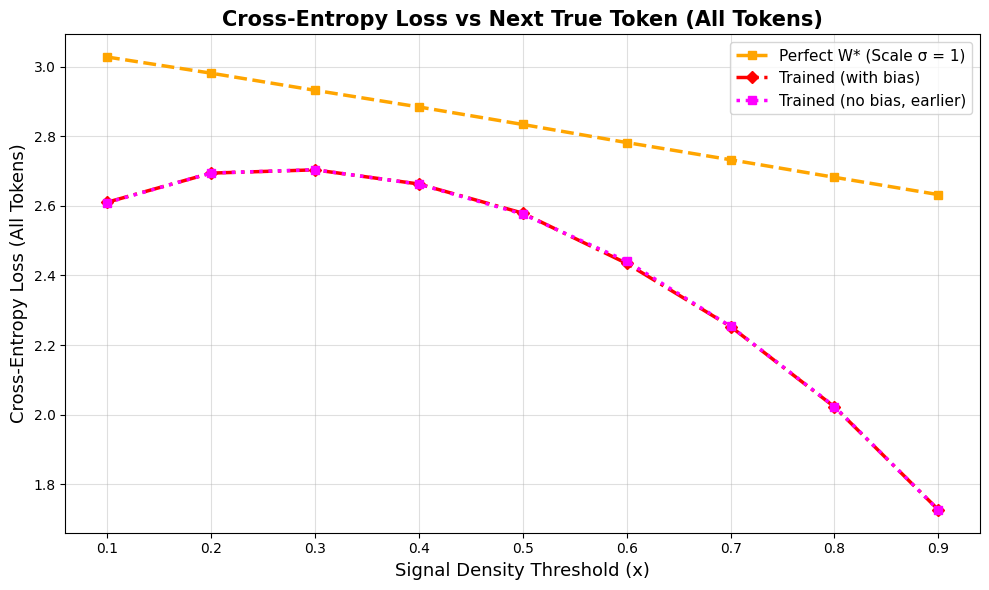

In [2]:
# --- 6. CE LOSS COMPARISON (Scaled vs Unscaled vs Trained vs Earlier) ---
def run_ce_loss_comparison():
    print(f">>> Running CE Loss Comparison on {CONFIG['device']}")
    
    model_scaled = PerfectInductionTransformer(query_type='ultimate').to(CONFIG['device']).eval()
    model_unscaled = PerfectInductionTransformer(query_type='ultimate').to(CONFIG['device']).eval()
    
    V = CONFIG['total_vocab']
    D = model_unscaled.attn_dim
    in2 = D + D
    
    W_fc_unscaled = torch.zeros(V, in2 + D, device=CONFIG['device'])
    W_fc_unscaled[0:V, in2:in2+V] = torch.eye(V, device=CONFIG['device']) * 1.0  
    model_unscaled.fc_out.weight.data = W_fc_unscaled

    loss_scaled_list = []
    loss_unscaled_list = []
    loss_trained_list = []
    loss_earlier_list = []

    for x in CONFIG['thresholds']:
        tx, ty = generate_fast_test_data(CONFIG['num_test_seqs'], x)
        dataset = torch.utils.data.TensorDataset(tx, ty)
        loader = torch.utils.data.DataLoader(dataset, batch_size=CONFIG['batch_size'], shuffle=False)

        trained_model_loaded = False
        earlier_model_loaded = False

        model_path = os.path.join(CONFIG['artifact_dir'], f"model_x_{x}.pth")
        if os.path.exists(model_path):
            trained_model = DisentangledTransformer().to(CONFIG['device'])
            trained_model.load_state_dict(torch.load(model_path, map_location=CONFIG['device']))
            trained_model.eval()
            trained_model_loaded = True
        else:
            print(f"Warning: Trained model not found at {model_path}")

        if CONFIG['compare_earlier']:
            earlier_path = os.path.join(CONFIG['earlier_artifact_dir'], f"model_x_{x}.pth")
            if os.path.exists(earlier_path):
                earlier_model = DisentangledTransformerNoBias().to(CONFIG['device'])
                earlier_model.load_state_dict(torch.load(earlier_path, map_location=CONFIG['device']))
                earlier_model.eval()
                earlier_model_loaded = True
            else:
                print(f"Warning: Earlier model not found at {earlier_path}")

        total_loss_scaled = 0.0
        total_loss_unscaled = 0.0
        total_loss_trained = 0.0
        total_loss_earlier = 0.0
        num_batches = 0

        for batch_x, batch_y in tqdm(loader, desc=f"Evaluating CE Loss x={x}"):
            batch_x, batch_y = batch_x.to(CONFIG['device']), batch_y.to(CONFIG['device'])
            
            with torch.no_grad():
                logits_scaled, _ = model_scaled(batch_x)
                logits_unscaled, _ = model_unscaled(batch_x)
                
                logits_scaled = logits_scaled.view(-1, V)
                logits_unscaled = logits_unscaled.view(-1, V)
                targets = batch_y.view(-1)
                
                total_loss_scaled += F.cross_entropy(logits_scaled, targets).item()
                total_loss_unscaled += F.cross_entropy(logits_unscaled, targets).item()
                
                if trained_model_loaded:
                    logits_trained, _ = trained_model(batch_x)
                    total_loss_trained += F.cross_entropy(logits_trained.view(-1, V), targets).item()

                if earlier_model_loaded:
                    logits_earlier, _ = earlier_model(batch_x)
                    total_loss_earlier += F.cross_entropy(logits_earlier.view(-1, V), targets).item()
                    
                num_batches += 1

        loss_scaled_list.append(total_loss_scaled / num_batches)
        loss_unscaled_list.append(total_loss_unscaled / num_batches)
        loss_trained_list.append(total_loss_trained / num_batches if trained_model_loaded else None)
        loss_earlier_list.append(total_loss_earlier / num_batches if earlier_model_loaded else None)

        if trained_model_loaded: del trained_model
        if earlier_model_loaded: del earlier_model
        torch.cuda.empty_cache()

    return loss_scaled_list, loss_unscaled_list, loss_trained_list, loss_earlier_list

def plot_ce_loss(loss_scaled, loss_unscaled, loss_trained, loss_earlier):
    x_vals = CONFIG['thresholds']
    
    trained_x = [x for x, val in zip(x_vals, loss_trained) if val is not None]
    trained_loss = [val for val in loss_trained if val is not None]

    earlier_x = [x for x, val in zip(x_vals, loss_earlier) if val is not None]
    earlier_loss = [val for val in loss_earlier if val is not None]
    
    plt.figure(figsize=(10, 6))
    
    # plt.plot(x_vals, loss_scaled, color='blue', marker='o', linestyle='-', linewidth=2.5, 
    #          label='Perfect W* (Scale σ = 50)')
    
    plt.plot(x_vals, loss_unscaled, color='orange', marker='s', linestyle='--', linewidth=2.5, 
             label='Perfect W* (Scale σ = 1)')
    
    if trained_loss:
        plt.plot(trained_x, trained_loss, color='red', marker='D', linestyle='-.', linewidth=2.5, 
                 label='Trained (with bias)')

    if CONFIG['compare_earlier'] and earlier_loss:
        plt.plot(earlier_x, earlier_loss, color='magenta', marker='s', linestyle=':', linewidth=2.5,
                 label='Trained (no bias, earlier)')
    
    plt.xlabel("Signal Density Threshold (x)", fontsize=13)
    plt.ylabel("Cross-Entropy Loss (All Tokens)", fontsize=13)
    plt.grid(True, alpha=0.4)
    plt.legend(loc='upper right', fontsize=11)
    plt.title("Cross-Entropy Loss vs Next True Token (All Tokens)", fontsize=15, fontweight='bold')
    
    plt.tight_layout()
    plt.savefig(f"{CONFIG['output_dir']}/ce_loss_scaling_vs_trained.png")
    plt.show()

# Execute the analysis
loss_scaled, loss_unscaled, loss_trained, loss_earlier = run_ce_loss_comparison()
plot_ce_loss(loss_scaled, loss_unscaled, loss_trained, loss_earlier)

#### Observation: with even bias i've almost same graph however those values are bit different
Now integrating with a bias in the construction and checking if the model cross entropy becomes better or not. 

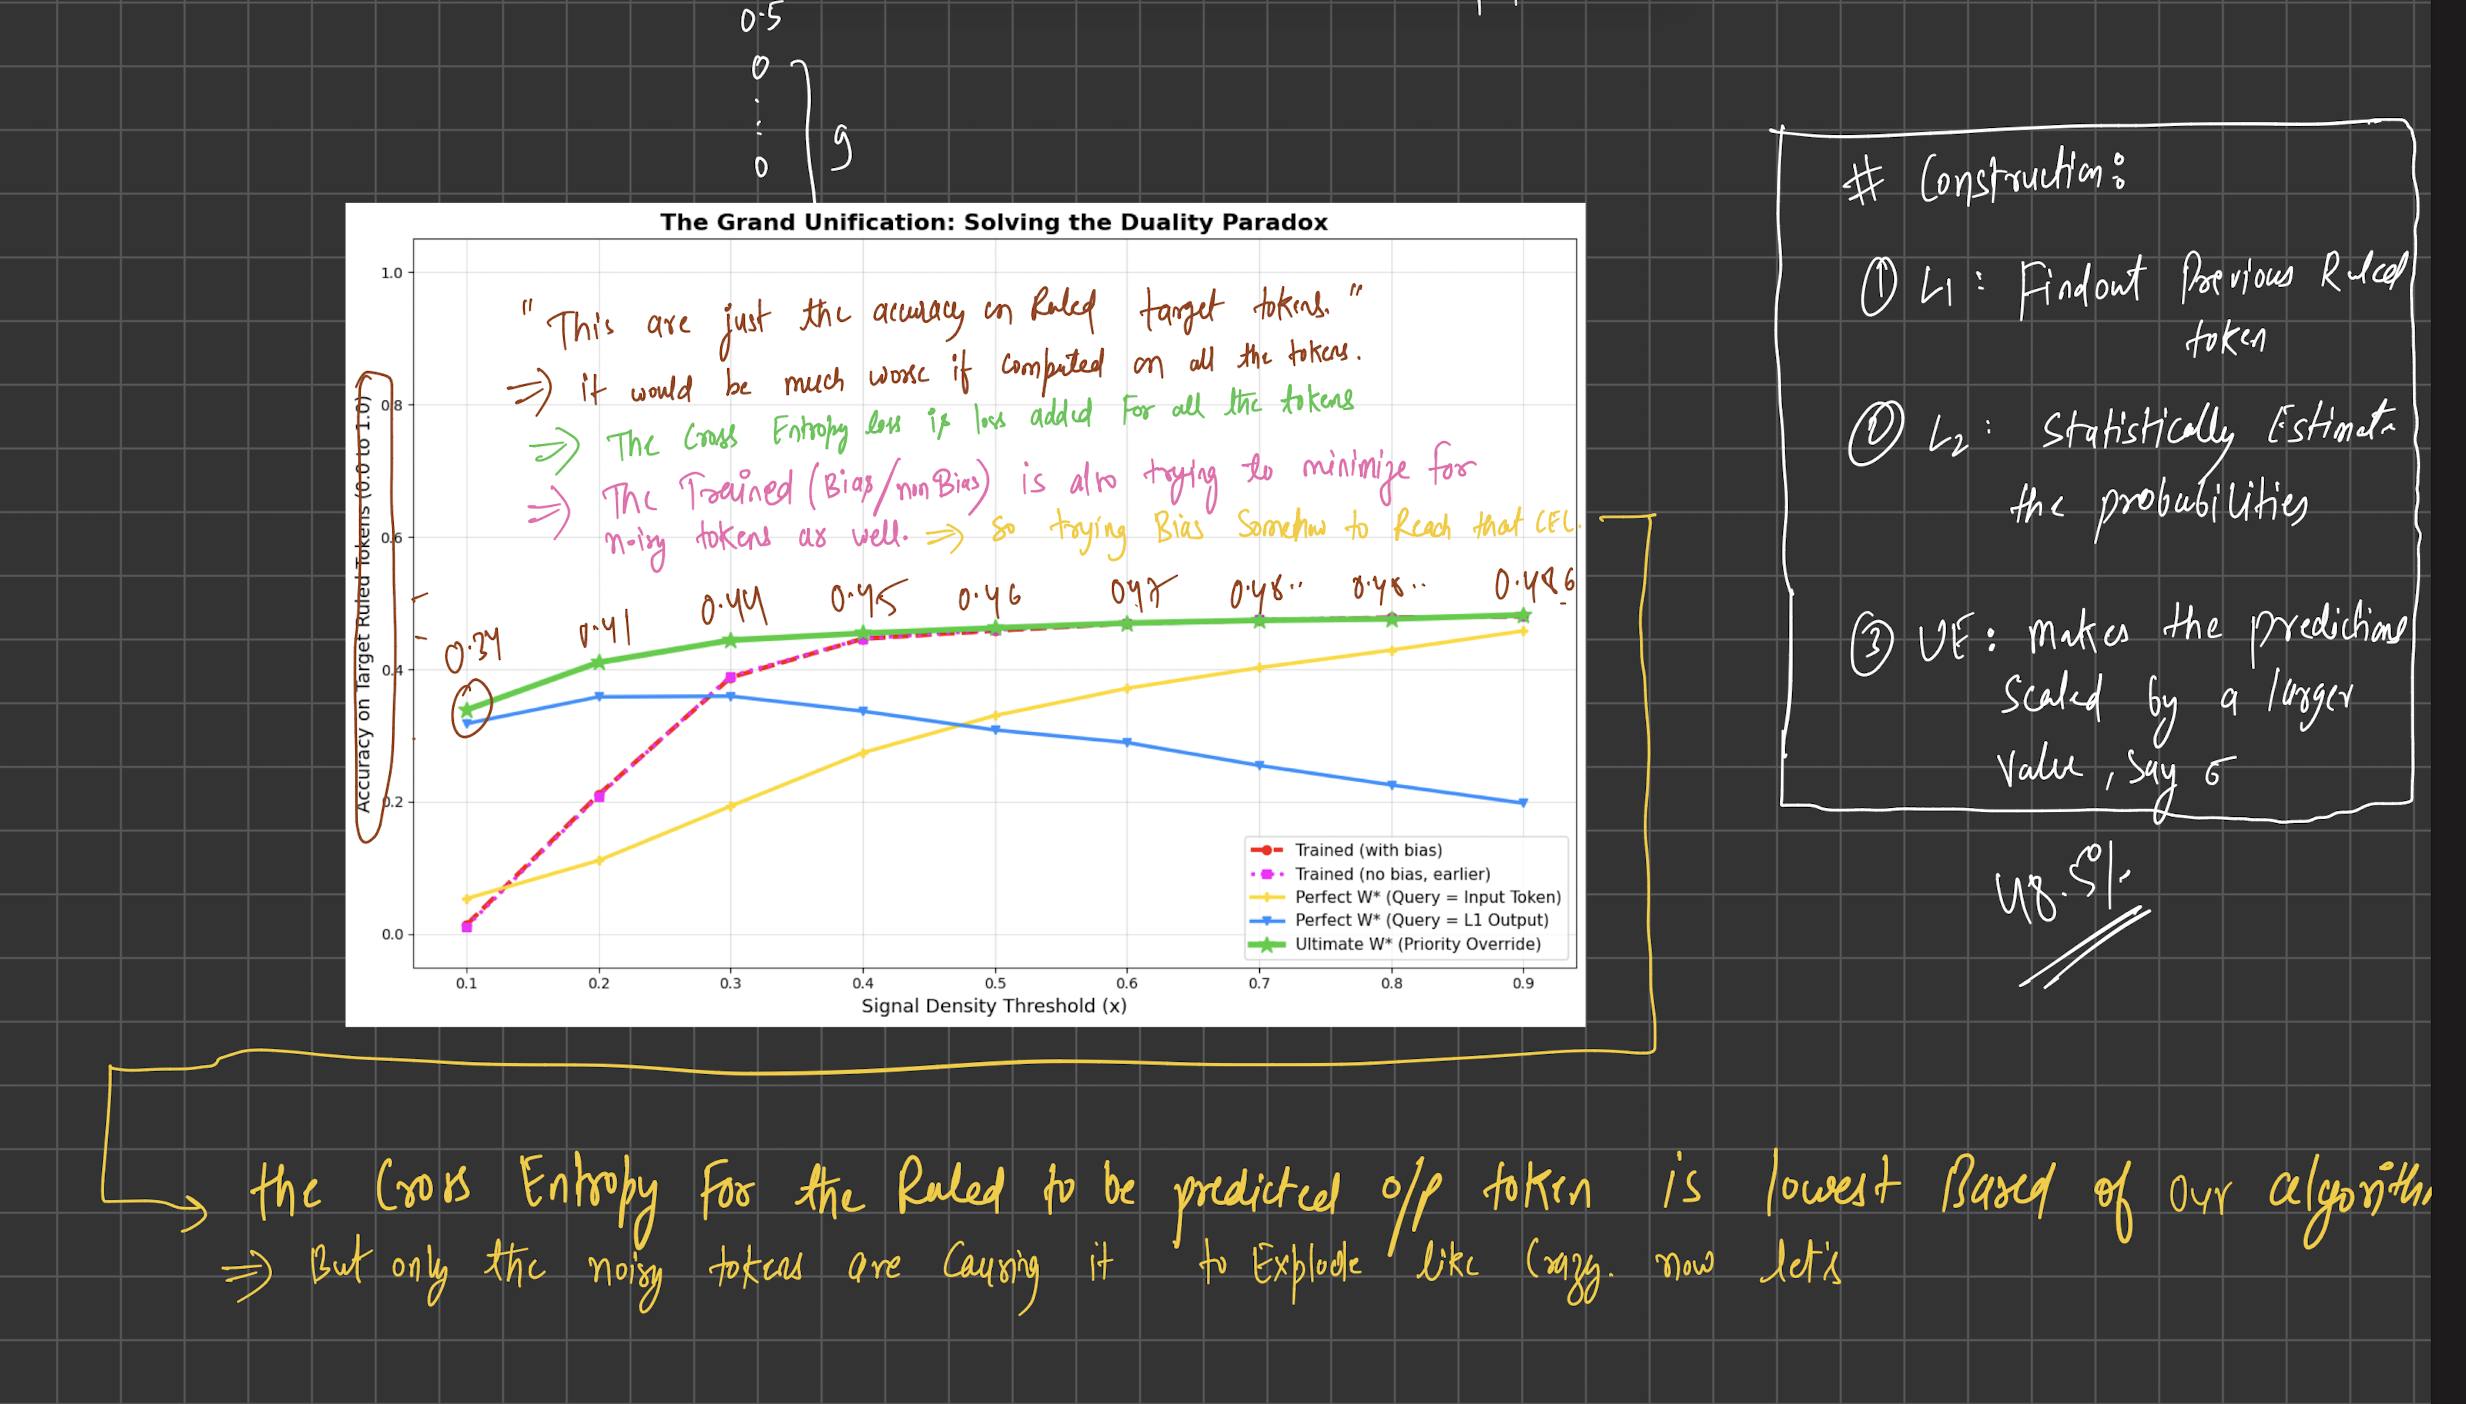

### I think the problem is the cross entropy loss on the noise token is exploding. so trying to plot the cross entropy loss seperatly for ruled and the noise token with our ultimate green construction and gradient descent trained with bias. 

x=0.1 (α=0.10)  WS hdg sig=2.485 nse=5.441 all=5.147 | Tr raw sig=4.287 nse=2.411 all=2.598 | Cn sig=2.996 nse=2.408 all=2.466 | Ctx sig=4.046 nse=2.408 all=2.571
x=0.2 (α=0.20)  WS hdg sig=1.882 nse=5.198 all=4.539 | Tr raw sig=3.169 nse=2.529 all=2.656 | Cn sig=2.303 nse=2.526 all=2.481 | Ctx sig=2.831 nse=2.526 all=2.586
x=0.3 (α=0.30)  WS hdg sig=1.605 nse=5.040 all=4.022 | Tr raw sig=2.605 nse=2.666 all=2.648 | Cn sig=1.897 nse=2.659 all=2.433 | Ctx sig=2.212 nse=2.659 all=2.527
x=0.4 (α=0.40)  WS hdg sig=1.469 nse=4.913 all=3.531 | Tr raw sig=2.210 nse=2.828 all=2.580 | Cn sig=1.609 nse=2.813 all=2.330 | Ctx sig=1.827 nse=2.813 all=2.417
x=0.5 (α=0.50)  WS hdg sig=1.358 nse=4.824 all=3.104 | Tr raw sig=1.947 nse=3.011 all=2.483 | Cn sig=1.386 nse=2.996 all=2.197 | Ctx sig=1.528 nse=2.996 all=2.267
x=0.6 (α=0.60)  WS hdg sig=1.304 nse=4.776 all=2.699 | Tr raw sig=1.705 nse=3.233 all=2.319 | Cn sig=1.204 nse=3.219 all=2.014 | Ctx sig=1.315 nse=3.219 all=2.081
x=0.7 (α=0.70)  WS hdg

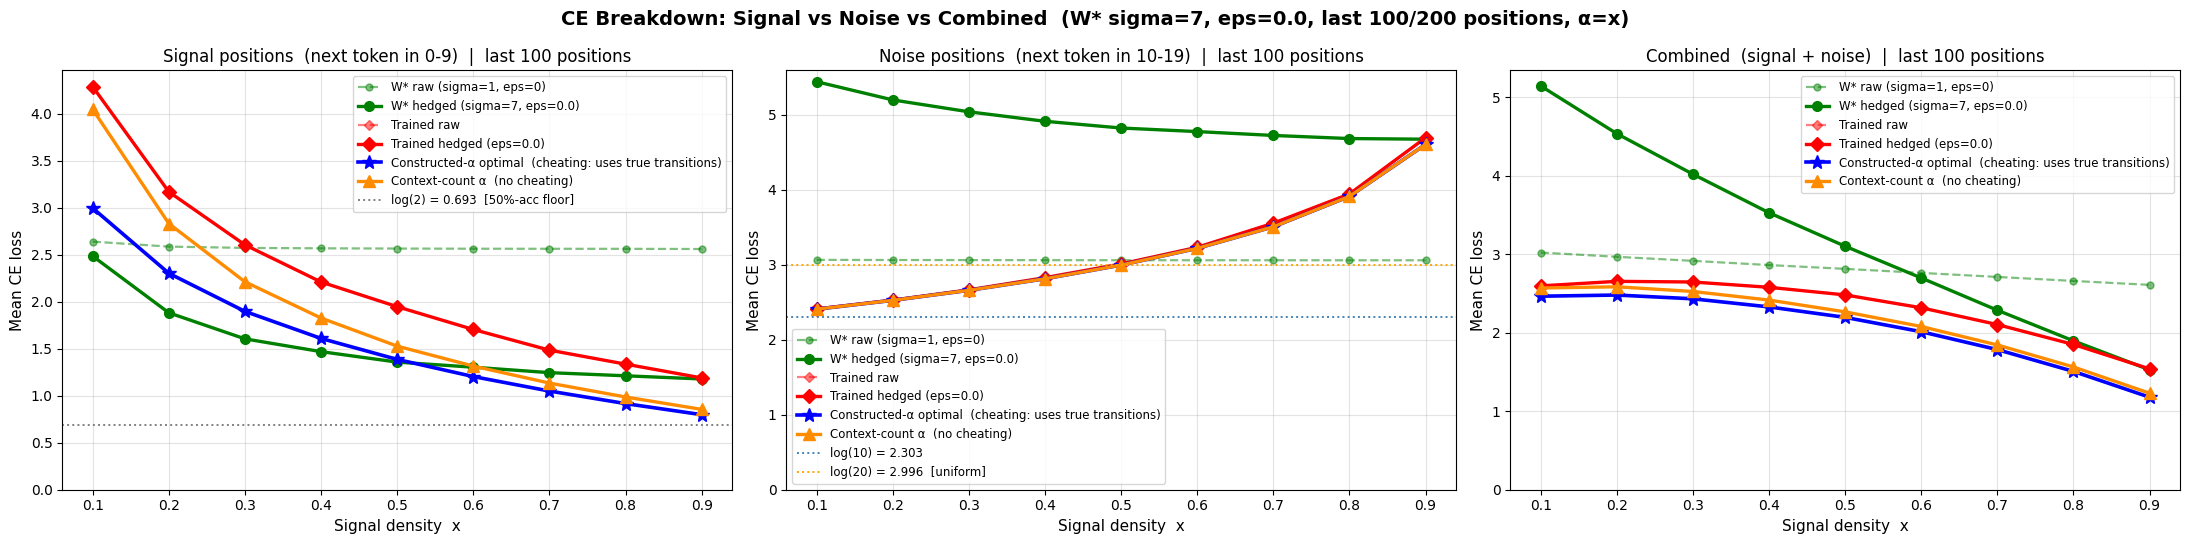

Saved -> artifacts_bias/ce_signal_noise_combined_s7_e0.0_last100.png


In [21]:

# ═══════════════════════════════════════════════════════════════════════════════
# CE BREAKDOWN: Signal positions vs Noise positions  vs  Combined
# W* (ultimate, green) vs Trained with bias (red) vs Constructed-α optimal (blue)
# Variants for W* and Trained:  raw (sigma=1, eps=0)  vs  hedged (sigma=CE_BREAK_SIGMA, eps=CE_BREAK_EPSILON)
#   p_hedge[k] = (1-eps)*softmax(sigma*logits)[k] + eps/(V - V_sig)   if k is a NOISE token
#   p_hedge[k] = (1-eps)*softmax(sigma*logits)[k]                     if k is a RULED token
#   (hedge mass is added ONLY to noise tokens, because a ruled token not in the
#    Markov-valid pair has zero probability under the true generator)
# CE_BREAK_LAST_N : only count CE on the LAST N positions of each sequence
# CE_BREAK_ALPHA  : list of α (one per threshold) for the constructed distribution.
#                   α = x is the provable global-min CE (= entropy of the true
#                   data-generating distribution at that threshold).
# ═══════════════════════════════════════════════════════════════════════════════

CE_BREAK_N_SEQS  = 500
CE_BREAK_SIGMA   = 7        # logit scale applied to W* before softmax
CE_BREAK_EPSILON = 0.0      # hedging: mix eps/V uniform into the distribution
CE_BREAK_LAST_N  = 100      # only score the last N positions per sequence (seq_len=200)
CE_BREAK_ALPHA   = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]   # one α per threshold; default α=x (optimal)

assert len(CE_BREAK_ALPHA) == len(CONFIG['thresholds']), \
    f"CE_BREAK_ALPHA must have length {len(CONFIG['thresholds'])}"


def hedged_ce(logits, targets, sigma, epsilon, V, V_sig):

    # Hedge mass goes only onto noise tokens (V_sig .. V-1).  Ruled tokens are
    # never boosted — a ruled token outside the Markov-valid pair has zero
    # probability in the true generator, so giving it hedge mass would waste
    # the budget and inflate CE.

    p = F.softmax(logits * sigma, dim=-1)
    n_noise    = V - V_sig
    noise_mass = epsilon / n_noise
    boost      = torch.zeros(V, device=p.device, dtype=p.dtype)
    boost[V_sig:] = noise_mass
    p_hedged   = (1.0 - epsilon) * p + boost            # broadcasts over batch
    p_target   = p_hedged.gather(1, targets.unsqueeze(1)).squeeze(1)
    return -torch.log(p_target.clamp(min=1e-9))


# ── data generator that ALSO returns each sequence's Markov transition table ──
def _generate_with_transitions(num_samples, threshold_x):
    V      = CONFIG['total_vocab']
    V_sig  = CONFIG['vocab_set1']
    x_data, y_data, trans_list = [], [], []
    for _ in range(num_samples):
        transitions = {i: np.random.choice(V_sig, size=2, replace=False)
                       for i in range(V_sig)}
        seq, last_ruled = [], None
        for _ in range(CONFIG['seq_len'] + 1):
            if np.random.rand() < threshold_x:
                tok = (np.random.randint(0, V_sig) if last_ruled is None
                       else int(np.random.choice(transitions[last_ruled])))
                last_ruled = tok
            else:
                tok = np.random.randint(V_sig, V)
            seq.append(tok)
        x_data.append(seq[:-1])
        y_data.append(seq[1:])
        trans_list.append(transitions)
    return torch.tensor(x_data), torch.tensor(y_data), trans_list


def _constructed_logq_at_targets(x_batch_np, y_batch_np, trans_list, alpha):
    
    """Return per-position -log q(y_t | x_{<=t}) under the α-distribution.

    Shape: (B, T).  q is a proper distribution at every position so q[y_t] > 0
    whenever y_t is a valid token from the generator (which it always is).
    """
    
    V      = CONFIG['total_vocab']
    V_sig  = CONFIG['vocab_set1']
    B, T   = x_batch_np.shape
    out    = np.empty((B, T), dtype=np.float64)
    log_a       = np.log(max(alpha, 1e-12))
    log_one_m_a = np.log(max(1.0 - alpha, 1e-12))
    log_V_sig   = np.log(V_sig)
    log_2       = np.log(2.0)

    for b in range(B):
        x_seq = x_batch_np[b]
        y_seq = y_batch_np[b]
        trans = trans_list[b]
        last_ruled = -1
        for t in range(T):
            # y[t] is the NEXT token after x[t] → conditioning prefix is x[0..t] INCLUSIVE.
            # Update last_ruled with x[t] BEFORE scoring y[t].
            xt = int(x_seq[t])
            if xt < V_sig:
                last_ruled = xt
            y = int(y_seq[t])
            if last_ruled == -1:
                # no ruled token in prefix → q uniform: α/V_sig on R, (1-α)/V_sig on N
                if y < V_sig:
                    out[b, t] = -(log_a - log_V_sig)
                else:
                    out[b, t] = -(log_one_m_a - log_V_sig)
            else:
                if y < V_sig:
                    r1, r2 = int(trans[last_ruled][0]), int(trans[last_ruled][1])
                    if y == r1 or y == r2:
                        out[b, t] = -(log_a - log_2)
                    else:
                        # q = 0 → infinite CE; shouldn't happen for data from same generator
                        out[b, t] = 50.0
                else:
                    out[b, t] = -(log_one_m_a - log_V_sig)
    return out


def _alpha_ce_from_context(x_batch_np, y_batch_np, alpha):
    
    """Context-count alpha CE — no cheating, uses only observed context."""
    
    V       = CONFIG['total_vocab']
    V_sig   = CONFIG['vocab_set1']
    n_noise = V - V_sig
    B, T    = x_batch_np.shape
    out     = np.empty((B, T), dtype=np.float64)
    eps     = 1e-02  # Laplace smoothing

    for b in range(B):
        x_seq = x_batch_np[b]
        y_seq = y_batch_np[b]
        trans_counts = np.zeros((V, V_sig), dtype=np.float64)
        pending      = np.zeros(V, dtype=np.float64)
        last_ruled   = -1

        for t in range(T):
            xt = int(x_seq[t])
            yt = int(y_seq[t])

            # Update state with x[t] first (same convention as constructed-α)
            if xt < V_sig:
                trans_counts[:, xt] += pending
                pending[:]   = 0.0
                pending[xt]  = 1.0
                last_ruled   = xt
            else:
                pending[xt] += 1.0

            # Score y[t]
            if last_ruled == -1:
                p = alpha / V_sig if yt < V_sig else (1.0 - alpha) / n_noise
                out[b, t] = -np.log(max(p, 1e-12))
            else:
                query  = xt if xt < V_sig else last_ruled
                cnt    = trans_counts[query]          # [V_sig]
                cnt_s  = cnt + eps
                tot_s  = cnt_s.sum()
                if yt < V_sig:
                    out[b, t] = -np.log(max(cnt_s[yt] / tot_s * alpha, 1e-12))
                else:
                    out[b, t] = -np.log(max((1.0 - alpha) / n_noise, 1e-12))
    return out


def run_ce_breakdown():
    device = CONFIG['device']
    V      = CONFIG['total_vocab']
    V_sig  = CONFIG['vocab_set1']
    T_full = CONFIG['seq_len']
    last_n = min(CE_BREAK_LAST_N, T_full)
    pos_cutoff = T_full - last_n   # positions >= cutoff are scored

    wstar = PerfectInductionTransformer(query_type='ultimate').to(device).eval()
    results = {}
    thresholds = list(CONFIG['thresholds'])

    for xi, x in enumerate(thresholds):
        alpha = float(CE_BREAK_ALPHA[xi])
        tx, ty, trans_list = _generate_with_transitions(CE_BREAK_N_SEQS, x)
        loader_idx = torch.utils.data.DataLoader(
            torch.utils.data.TensorDataset(tx, ty, torch.arange(len(tx))),
            batch_size=CONFIG['batch_size'], shuffle=False)

        model_path = os.path.join(CONFIG['artifact_dir'], f"model_x_{x}.pth")
        trained_loaded = False
        if os.path.exists(model_path):
            trained = DisentangledTransformer().to(device)
            trained.load_state_dict(torch.load(model_path, map_location=device))
            trained.eval()
            trained_loaded = True

        buckets = {k: [] for k in [
            'ws_raw_sig', 'ws_raw_nse', 'ws_raw_all',
            'ws_hdg_sig', 'ws_hdg_nse', 'ws_hdg_all',
            'tr_raw_sig', 'tr_raw_nse', 'tr_raw_all',
            'tr_hdg_sig', 'tr_hdg_nse', 'tr_hdg_all',
            'cn_sig',     'cn_nse',     'cn_all',
            'ctx_sig',    'ctx_nse',    'ctx_all',
        ]}

        for bx, by, bidx in loader_idx:
            bx, by = bx.to(device), by.to(device)
            B, T = by.shape
            flat_y = by.reshape(-1)
            is_sig = flat_y < V_sig
            is_nse = ~is_sig

            pos_idx  = torch.arange(T, device=device).unsqueeze(0).expand(B, T).reshape(-1)
            is_late  = pos_idx >= pos_cutoff
            sig_mask = is_sig & is_late
            nse_mask = is_nse & is_late
            all_mask = is_late

            with torch.no_grad():
                ws_logits = wstar(bx)[0].reshape(-1, V)
                ws_ce_raw = F.cross_entropy(ws_logits, flat_y, reduction='none')
                ws_ce_hdg = hedged_ce(ws_logits, flat_y, CE_BREAK_SIGMA, CE_BREAK_EPSILON, V, V_sig)

                for ce, sk, nk, ak in [
                    (ws_ce_raw, 'ws_raw_sig', 'ws_raw_nse', 'ws_raw_all'),
                    (ws_ce_hdg, 'ws_hdg_sig', 'ws_hdg_nse', 'ws_hdg_all')
                ]:
                    if sig_mask.any(): buckets[sk].append(ce[sig_mask].mean().item())
                    if nse_mask.any(): buckets[nk].append(ce[nse_mask].mean().item())
                    if all_mask.any(): buckets[ak].append(ce[all_mask].mean().item())

                if trained_loaded:
                    tr_logits = trained(bx)[0].reshape(-1, V)
                    tr_ce_raw = F.cross_entropy(tr_logits, flat_y, reduction='none')
                    tr_ce_hdg = hedged_ce(tr_logits, flat_y, 1.0, CE_BREAK_EPSILON, V, V_sig)

                    for ce, sk, nk, ak in [
                        (tr_ce_raw, 'tr_raw_sig', 'tr_raw_nse', 'tr_raw_all'),
                        (tr_ce_hdg, 'tr_hdg_sig', 'tr_hdg_nse', 'tr_hdg_all')
                    ]:
                        if sig_mask.any(): buckets[sk].append(ce[sig_mask].mean().item())
                        if nse_mask.any(): buckets[nk].append(ce[nse_mask].mean().item())
                        if all_mask.any(): buckets[ak].append(ce[all_mask].mean().item())

            # Constructed-α CE (CPU, per-sequence)
            x_np = bx.detach().cpu().numpy()
            y_np = by.detach().cpu().numpy()
            sub_trans = [trans_list[i] for i in bidx.tolist()]
            ce_cn = _constructed_logq_at_targets(x_np, y_np, sub_trans, alpha)   # (B, T)
            ce_cn_flat = torch.from_numpy(ce_cn.reshape(-1)).to(device).float()
            if sig_mask.any(): buckets['cn_sig'].append(ce_cn_flat[sig_mask].mean().item())
            if nse_mask.any(): buckets['cn_nse'].append(ce_cn_flat[nse_mask].mean().item())
            if all_mask.any(): buckets['cn_all'].append(ce_cn_flat[all_mask].mean().item())

            # Context-count α CE (no cheating — uses only observed context)
            ce_ctx      = _alpha_ce_from_context(x_np, y_np, alpha)   # (B, T)
            ce_ctx_flat = torch.from_numpy(ce_ctx.reshape(-1)).to(device).float()
            if sig_mask.any(): buckets['ctx_sig'].append(ce_ctx_flat[sig_mask].mean().item())
            if nse_mask.any(): buckets['ctx_nse'].append(ce_ctx_flat[nse_mask].mean().item())
            if all_mask.any(): buckets['ctx_all'].append(ce_ctx_flat[all_mask].mean().item())

        def _m(lst): return float(np.nanmean(lst)) if lst else float('nan')
        results[x] = {k: _m(v) for k, v in buckets.items()}
        results[x]['alpha'] = alpha

        if trained_loaded: del trained
        torch.cuda.empty_cache()
        print(f"x={x:.1f} (α={alpha:.2f})  "
              f"WS hdg sig={results[x]['ws_hdg_sig']:.3f} nse={results[x]['ws_hdg_nse']:.3f} all={results[x]['ws_hdg_all']:.3f} | "
              f"Tr raw sig={results[x]['tr_raw_sig']:.3f} nse={results[x]['tr_raw_nse']:.3f} all={results[x]['tr_raw_all']:.3f} | "
              f"Cn sig={results[x]['cn_sig']:.3f} nse={results[x]['cn_nse']:.3f} all={results[x]['cn_all']:.3f} | "
              f"Ctx sig={results[x]['ctx_sig']:.3f} nse={results[x]['ctx_nse']:.3f} all={results[x]['ctx_all']:.3f}")

    return results


def plot_ce_breakdown(results):
    xs  = sorted(results.keys())
    def _g(k): return [results[x][k] for x in xs]
    V     = CONFIG['total_vocab']
    V_sig = CONFIG['vocab_set1']

    fig, axes = plt.subplots(1, 3, figsize=(22, 5.5))
    fig.suptitle(
        f"CE Breakdown: Signal vs Noise vs Combined  "
        f"(W* sigma={CE_BREAK_SIGMA}, eps={CE_BREAK_EPSILON}, last {CE_BREAK_LAST_N}/{CONFIG['seq_len']} positions, α=x)",
        fontsize=14, fontweight='bold')

    panels = [
        ('Signal positions  (next token in 0-9)',
         'ws_raw_sig', 'ws_hdg_sig', 'tr_raw_sig', 'tr_hdg_sig', 'cn_sig', 'ctx_sig',
         [(np.log(2), 'gray',      f'log(2) = {np.log(2):.3f}  [50%-acc floor]')]),
        ('Noise positions  (next token in 10-19)',
         'ws_raw_nse', 'ws_hdg_nse', 'tr_raw_nse', 'tr_hdg_nse', 'cn_nse', 'ctx_nse',
         [(np.log(V_sig), 'steelblue', f'log(10) = {np.log(V_sig):.3f}'),
          (np.log(V),     'orange',    f'log(20) = {np.log(V):.3f}  [uniform]')]),
        ('Combined  (signal + noise)',
         'ws_raw_all', 'ws_hdg_all', 'tr_raw_all', 'tr_hdg_all', 'cn_all', 'ctx_all',
         []),
    ]

    for ax, (title, k_wsr, k_wsh, k_trr, k_trh, k_cn, k_ctx, hlines) in zip(axes, panels):
        ax.plot(xs, _g(k_wsr), 'g--o', lw=1.6, ms=5, alpha=0.5, label='W* raw (sigma=1, eps=0)')
        ax.plot(xs, _g(k_wsh), 'g-o',  lw=2.4, ms=7, label=f'W* hedged (sigma={CE_BREAK_SIGMA}, eps={CE_BREAK_EPSILON})')
        ax.plot(xs, _g(k_trr), 'r--D', lw=1.6, ms=5, alpha=0.5, label='Trained raw')
        ax.plot(xs, _g(k_trh), 'r-D',  lw=2.4, ms=7, label=f'Trained hedged (eps={CE_BREAK_EPSILON})')
        ax.plot(xs, _g(k_cn),  'b-*',  lw=2.6, ms=10, label='Constructed-α optimal  (cheating: uses true transitions)')
        ax.plot(xs, _g(k_ctx), color='darkorange', marker='^', ls='-', lw=2.4, ms=8, label='Context-count α  (no cheating)')
        for yv, c, lab in hlines:
            ax.axhline(yv, color=c, ls=':', lw=1.4, label=lab)
        ax.set_title(f"{title}  |  last {CE_BREAK_LAST_N} positions", fontsize=12)
        ax.set_xlabel("Signal density  x", fontsize=11)
        ax.set_ylabel("Mean CE loss", fontsize=11)
        ax.legend(fontsize=8.5, loc='best')
        ax.grid(True, alpha=0.35)
        ax.set_ylim(bottom=0)

    plt.tight_layout()
    out = f"{CONFIG['output_dir']}/ce_signal_noise_combined_s{CE_BREAK_SIGMA}_e{CE_BREAK_EPSILON}_last{CE_BREAK_LAST_N}.png"
    plt.savefig(out, dpi=150)
    plt.show()
    print(f"Saved -> {out}")


ce_results = run_ce_breakdown()
plot_ce_breakdown(ce_results)


In [ ]:
# ══ ADD W*-better (purple) to the Signal / Noise / Combined CE breakdown ══════
# W*-better = W*("ultimate") logits read out PRE-softmax as  σ·logits + bN·(noise
# mask).  (σ, bN) are calibrated per-threshold on a held-out batch (2-D grid).
# Reuses helpers defined in the breakdown cell above:
#   _generate_with_transitions, _alpha_ce_from_context, _constructed_logq_at_targets,
#   hedged_ce, PerfectInductionTransformer, DisentangledTransformer.
import numpy as np, torch, torch.nn.functional as F, os
import matplotlib.pyplot as plt

device = CONFIG['device']; V = CONFIG['total_vocab']; Vs = CONFIG['vocab_set1']
T = CONFIG['seq_len']; last_n = min(CE_BREAK_LAST_N, T); cutoff = T - last_n
nmask = torch.zeros(V, device=device); nmask[Vs:] = 1.0
wstar = PerfectInductionTransformer(query_type='ultimate').to(device).eval()

def _late_mask(B):
    pos = torch.arange(T, device=device).unsqueeze(0).expand(B, T).reshape(-1)
    return pos >= cutoff

def _fit_sig_bN(Lflat, yflat, mask,
                sig_grid=np.arange(0.5, 12.01, 0.5), bN_grid=np.arange(-3.0, 6.01, 0.5)):
    Ll = Lflat[mask]; yl = yflat[mask]; best = (float('inf'), (CE_BREAK_SIGMA, 0.0))
    for sig in sig_grid:
        for bN in bN_grid:
            ce = F.cross_entropy(Ll * float(sig) + nmask * float(bN), yl).item()
            if ce < best[0]: best = (ce, (float(sig), float(bN)))
    return best[1]

wb_res = {}
for xi, x in enumerate(CONFIG['thresholds']):
    alpha = float(CE_BREAK_ALPHA[xi])
    # calibration batch → fit (σ, bN) on late positions
    cx, cy, _ = _generate_with_transitions(150, x)
    with torch.no_grad():
        Lc = wstar(cx.to(device))[0].reshape(-1, V); yc = cy.to(device).reshape(-1)
    sig, bN = _fit_sig_bN(Lc, yc, _late_mask(cy.shape[0]))
    # eval data (batched, same style as the breakdown cell)
    tx, ty, trl = _generate_with_transitions(CE_BREAK_N_SEQS, x)
    tr_path = os.path.join(CONFIG['artifact_dir'], f"model_x_{x}.pth")
    trained = None
    if os.path.exists(tr_path):
        trained = DisentangledTransformer().to(device)
        trained.load_state_dict(torch.load(tr_path, map_location=device)); trained.eval()
    buck = {k: [] for k in ['wb_sig','wb_nse','wb_all','tr_sig','tr_nse','tr_all',
                            'wsh_sig','wsh_nse','wsh_all','cn_sig','cn_nse','cn_all',
                            'ctx_sig','ctx_nse','ctx_all']}
    loader = torch.utils.data.DataLoader(
        torch.utils.data.TensorDataset(tx, ty, torch.arange(len(tx))),
        batch_size=CONFIG['batch_size'], shuffle=False)
    for bx, by, bidx in loader:
        bx, by = bx.to(device), by.to(device); B, Tt = by.shape; fy = by.reshape(-1)
        late = _late_mask(B); issig = fy < Vs; sm = late & issig; nm = late & (~issig)
        with torch.no_grad():
            Lws = wstar(bx)[0].reshape(-1, V)
            wb  = F.cross_entropy(Lws * sig + nmask * bN, fy, reduction='none')
            wsh = hedged_ce(Lws, fy, CE_BREAK_SIGMA, CE_BREAK_EPSILON, V, Vs)
            tr  = (F.cross_entropy(trained(bx)[0].reshape(-1, V), fy, reduction='none')
                   if trained is not None else None)
        xnp = bx.cpu().numpy(); ynp = by.cpu().numpy(); st = [trl[i] for i in bidx.tolist()]
        cn  = torch.from_numpy(_constructed_logq_at_targets(xnp, ynp, st, alpha).reshape(-1)).to(device).float()
        ctx = torch.from_numpy(_alpha_ce_from_context(xnp, ynp, alpha).reshape(-1)).to(device).float()
        def add(pre, ce):
            if sm.any():   buck[pre+'_sig'].append(ce[sm].mean().item())
            if nm.any():   buck[pre+'_nse'].append(ce[nm].mean().item())
            if late.any(): buck[pre+'_all'].append(ce[late].mean().item())
        add('wb', wb); add('wsh', wsh); add('cn', cn); add('ctx', ctx)
        if tr is not None: add('tr', tr)
    wb_res[x] = {k: (float(np.nanmean(v)) if v else float('nan')) for k, v in buck.items()}
    wb_res[x]['sig'] = sig; wb_res[x]['bN'] = bN
    if trained is not None: del trained
    if device.startswith('cuda'): torch.cuda.empty_cache()
    print(f"x={x:.1f} (sigma={sig:.1f}, bN={bN:+.1f})  "
          f"WB sig={wb_res[x]['wb_sig']:.3f} nse={wb_res[x]['wb_nse']:.3f} all={wb_res[x]['wb_all']:.3f}")

# ── plot: same 1x3 panels, now WITH the purple W*-better curve ────────────────
xs = sorted(wb_res.keys()); g = lambda k: [wb_res[x][k] for x in xs]
fig, axes = plt.subplots(1, 3, figsize=(22, 5.5))
fig.suptitle(f"CE Breakdown + W*-better (purple)   (last {last_n}/{T} positions, alpha=x)",
             fontsize=14, fontweight='bold')
panels = [('Signal positions  (next token in 0-9)',  'wb_sig','tr_sig','wsh_sig','cn_sig','ctx_sig'),
          ('Noise positions  (next token in 10-19)',  'wb_nse','tr_nse','wsh_nse','cn_nse','ctx_nse'),
          ('Combined  (signal + noise)',              'wb_all','tr_all','wsh_all','cn_all','ctx_all')]
for ax, (title, kwb, ktr, kwsh, kcn, kctx) in zip(axes, panels):
    ax.plot(xs, g(kwsh), 'g-o', lw=2,   ms=6, label=f'W* hedged (sigma={CE_BREAK_SIGMA})')
    ax.plot(xs, g(ktr),  'r-D', lw=2,   ms=6, label='Trained with bias')
    ax.plot(xs, g(kwb),  '-s',  color='purple', lw=2.6, ms=7, label='W*-better (per-alpha sigma + noise bias)')
    ax.plot(xs, g(kcn),  'b-*', lw=2.2, ms=9, label='Constructed-alpha (cheating: true transitions)')
    ax.plot(xs, g(kctx), color='darkorange', marker='^', ls='-', lw=2, ms=7, label='Context-count alpha (no cheating)')
    ax.set_title(title, fontsize=12); ax.set_xlabel('signal density  x', fontsize=11)
    ax.set_ylabel('mean CE loss', fontsize=11); ax.grid(True, alpha=0.35)
    ax.legend(fontsize=8.5, loc='best'); ax.set_ylim(bottom=0)
plt.tight_layout()
out = f"{CONFIG['output_dir']}/ce_breakdown_with_wbetter.png"
plt.savefig(out, dpi=150); plt.show(); print('Saved ->', out)


### checking first if my handconstruction is giving correct probability distributions or not. 

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# W* PROBABILITY DIAGNOSTIC — compact view
#   Show:  the last few tokens of one test sequence  |  W*'s prediction
#          + the Markov chain that generated the sequence (so you can verify
#            what *should* follow each ruled token)
#          + bar chart of P(· | context) at one chosen position
#
#   Knobs:
#     INSPECT_THRESH   data-generation threshold
#     INSPECT_N_SEQS   how many sequences to generate (then pick SEQ_IDX)
#     SEQ_IDX          which sequence to inspect (0..N-1)
#     RANGE_START / RANGE_END   slice of positions to print  (end exclusive;
#                              defaults: last 50 positions)
#     FOCUS_POS        position whose probability bar chart is shown
#                      (absolute index in [0, T-1]; default = last position
#                      of the printed range)
#     INSPECT_SIGMA / INSPECT_EPSILON   hedge:
#         p_hedge[k] = (1-eps)*softmax(σ*logits)[k] + eps/(V-V_sig)  if k is noise
#         p_hedge[k] = (1-eps)*softmax(σ*logits)[k]                       if k is ruled
# ═══════════════════════════════════════════════════════════════════════════════

INSPECT_THRESH   = 0.6
INSPECT_N_SEQS   = 5
SEQ_IDX          = 0
RANGE_START      = 150   # None → seq_len - 50
RANGE_END        = 200   # None → seq_len
FOCUS_POS        = 160   # None → RANGE_END - 1  (last printed position)
INSPECT_SIGMA    = 5.5
INSPECT_EPSILON  = 0
INSPECT_SEED     = 42


def _inspect_generate(num_samples, threshold_x):
    """Same generator as the CE-breakdown cell, but also returns the transitions
    table for each sequence so we can show the ground-truth Markov chain."""
    V      = CONFIG['total_vocab']
    V_sig  = CONFIG['vocab_set1']
    x_data, y_data, trans_list = [], [], []
    for _ in range(num_samples):
        transitions = {i: np.random.choice(V_sig, size=2, replace=False)
                       for i in range(V_sig)}
        seq, last_ruled = [], None
        for _ in range(CONFIG['seq_len'] + 1):
            if np.random.rand() < threshold_x:
                tok = (np.random.randint(0, V_sig) if last_ruled is None
                       else int(np.random.choice(transitions[last_ruled])))
                last_ruled = tok
            else:
                tok = np.random.randint(V_sig, V)
            seq.append(tok)
        x_data.append(seq[:-1])
        y_data.append(seq[1:])
        trans_list.append(transitions)
    return torch.tensor(x_data), torch.tensor(y_data), trans_list


def inspect_wstar():
    device = CONFIG['device']
    V      = CONFIG['total_vocab']
    V_sig  = CONFIG['vocab_set1']
    T      = CONFIG['seq_len']

    if INSPECT_SEED is not None:
        torch.manual_seed(INSPECT_SEED); np.random.seed(INSPECT_SEED)

    rs = 0 if RANGE_START is None else max(0, int(RANGE_START))
    re = T if RANGE_END   is None else min(T, int(RANGE_END))
    if RANGE_START is None and RANGE_END is None:
        rs = max(0, T - 50)
    assert 0 <= rs < re <= T, f"bad range [{rs}, {re}) for T={T}"
    fp = (re - 1) if FOCUS_POS is None else int(FOCUS_POS)
    assert 0 <= fp < T, f"FOCUS_POS={fp} out of [0,{T})"

    tx, ty, trans_list = _inspect_generate(INSPECT_N_SEQS, INSPECT_THRESH)
    assert 0 <= SEQ_IDX < INSPECT_N_SEQS
    x_seq      = tx[SEQ_IDX].to(device)
    y_seq      = ty[SEQ_IDX].to(device)
    transitions = trans_list[SEQ_IDX]   # {r: array([r1, r2])} for r in 0..V_sig-1

    wstar = PerfectInductionTransformer(query_type='ultimate').to(device).eval()
    with torch.no_grad():
        logits   = wstar(x_seq.unsqueeze(0))[0].squeeze(0)              # (T, V)
        p_soft   = F.softmax(logits * INSPECT_SIGMA, dim=-1)
        n_noise  = V - V_sig
        boost    = torch.zeros(V, device=device, dtype=p_soft.dtype)
        boost[V_sig:] = INSPECT_EPSILON / n_noise
        probs    = (1.0 - INSPECT_EPSILON) * p_soft + boost
        pred     = probs.argmax(dim=-1)

    # Trained-with-bias model distribution at the same positions
    model_path = os.path.join(CONFIG['artifact_dir'], f"model_x_{INSPECT_THRESH}.pth")
    trained_probs = None; trained_pred = None
    if os.path.exists(model_path):
        trained = DisentangledTransformer().to(device)
        trained.load_state_dict(torch.load(model_path, map_location=device))
        trained.eval()
        with torch.no_grad():
            tr_logits = trained(x_seq.unsqueeze(0))[0].squeeze(0)        # (T, V)
            trained_probs = F.softmax(tr_logits, dim=-1)
            trained_pred  = trained_probs.argmax(dim=-1)
        del trained
        if device != 'cpu': torch.cuda.empty_cache()
    else:
        print(f"WARN: trained checkpoint not found at {model_path}")

    # ── W*-better: readout σ·logits + bN on noise tokens (per-α calibration) ──
    import numpy as _np2
    nmask_wb = torch.zeros(V, device=device); nmask_wb[V_sig:] = 1.0
    _last_n = 100; _cut = T - _last_n
    _np2.random.seed(777)
    _cx, _cy, _ = _inspect_generate(150, INSPECT_THRESH)
    with torch.no_grad():
        _Lc = wstar(_cx.to(device))[0].reshape(-1, V); _yc = _cy.to(device).reshape(-1)
    _pos = torch.arange(T, device=device).expand(_cy.shape[0], T).reshape(-1); _late = _pos >= _cut
    _best = (float("inf"), (INSPECT_SIGMA, 0.0))
    for _sg in _np2.arange(0.5, 12.01, 0.5):
        for _bn in _np2.arange(-3.0, 6.01, 0.5):
            _ce = F.cross_entropy(_Lc[_late] * float(_sg) + nmask_wb * float(_bn), _yc[_late]).item()
            if _ce < _best[0]: _best = (_ce, (float(_sg), float(_bn)))
    wb_sigma, wb_bN = _best[1]
    with torch.no_grad():
        wb_probs = F.softmax(logits * wb_sigma + nmask_wb * wb_bN, dim=-1)
    wb_pb_np = wb_probs.cpu().numpy(); wb_pr_np = wb_probs.argmax(dim=-1).cpu().numpy()
    print(f"W*-better calibrated: sigma={wb_sigma:.1f}, bN={wb_bN:+.1f}")

    x_np  = x_seq.cpu().numpy()
    y_np  = y_seq.cpu().numpy()
    pr_np = pred.cpu().numpy()
    pb_np = probs.cpu().numpy()
    tr_pb_np = trained_probs.cpu().numpy() if trained_probs is not None else None
    tr_pr_np = trained_pred.cpu().numpy()  if trained_pred  is not None else None

    fp_tok_loc = int(x_np[fp])

    # Context-count α distribution at fp (no cheating: uses observed context only)
    ctx_trans   = np.zeros((V, V_sig), dtype=np.float64)
    ctx_pending = np.zeros(V, dtype=np.float64)
    ctx_last_ruled = -1
    for i in range(fp + 1):
        xt_i = int(x_np[i])
        if xt_i < V_sig:
            ctx_trans[:, xt_i] += ctx_pending
            ctx_pending[:]    = 0.0
            ctx_pending[xt_i] = 1.0
            ctx_last_ruled    = xt_i
        else:
            ctx_pending[xt_i] += 1.0
    query_ctx   = fp_tok_loc if fp_tok_loc < V_sig else max(ctx_last_ruled, 0)
    eps_ctx      = 0.1  # Laplace smoothing — matches CE curve implementation
    ctx_cnt_raw  = ctx_trans[query_ctx]          # [V_sig] raw counts
    ctx_cnt_s    = ctx_cnt_raw + eps_ctx         # Laplace-smoothed
    ctx_tot_s    = ctx_cnt_s.sum()
    ctx_probs_fp = np.zeros(V, dtype=np.float64)
    ctx_probs_fp[:V_sig] = ctx_cnt_s / ctx_tot_s * INSPECT_THRESH
    ctx_probs_fp[V_sig:] = (1.0 - INSPECT_THRESH) / (V - V_sig)

    # ── header + Markov chain printout ───────────────────────────────────────
    print(f"Sequence {SEQ_IDX}  |  threshold x={INSPECT_THRESH}  "
          f"|  positions [{rs}, {re})  |  T={T}")
    print(f"hedge: σ={INSPECT_SIGMA}, ε={INSPECT_EPSILON}\n")
    print("Markov chain (ruled-token transitions for this sequence):")
    for r in range(V_sig):
        r1, r2 = int(transitions[r][0]), int(transitions[r][1])
        print(f"   {r} → {{{r1}, {r2}}}")
    print()

    # ── compact printout: position | input | target | W* pred | ✓/✗ ──────────
    print(f"  {'pos':>4}  {'x[t]':>4}  {'y[t]':>4}  {'pred':>4}  {'ok':>3}  "
          f"{'p(y[t])':>9}  expected next")
    print(f"  {'-'*4}  {'-'*4}  {'-'*4}  {'-'*4}  {'-'*3}  {'-'*9}  {'-'*22}")
    for t in range(rs, re):
        ok  = '✓' if pr_np[t] == y_np[t] else '✗'
        ptg = pb_np[t, y_np[t]]
        # what the chain says SHOULD follow x[t]:
        if x_np[t] < V_sig:
            r1, r2 = int(transitions[x_np[t]][0]), int(transitions[x_np[t]][1])
            exp = f"ruled → {{{r1}, {r2}}}"
        else:
            exp = "noise prefix (uniform)"
        marker = '  ←FP' if t == fp else ''
        print(f"  {t:>4}  {x_np[t]:>4}  {y_np[t]:>4}  {pr_np[t]:>4}  {ok:>3}  "
              f"{ptg:9.4f}  {exp}{marker}")

    n_correct = int((pr_np[rs:re] == y_np[rs:re]).sum())
    print(f"\n  accuracy on shown range: {n_correct}/{re-rs} = {n_correct/(re-rs):.2%}")
    fp_tok_print = int(x_np[fp])
    prior_count_print = int((x_np[:fp] == fp_tok_print).sum())
    print(f"  x[FOCUS_POS={fp}] = {fp_tok_print}  appeared {prior_count_print}× in x[0..{fp-1}]")

    # Expected continuations at FOCUS_POS (used to highlight on the bar chart)
    if x_np[fp] < V_sig:
        r1_fp, r2_fp = int(transitions[x_np[fp]][0]), int(transitions[x_np[fp]][1])
        expected_at_fp = (r1_fp, r2_fp)
    else:
        expected_at_fp = None   # noise prefix → no specific Markov continuation

    # ── compact figure: token strip + W* bar + Trained bar ───────────────────
    BLUE = '#1f6feb'; ORANGE = '#e07a18'; GRAY = '#bfc4cb'
    RED  = '#d62828'; GREEN = '#2a9d4a'
    has_trained = tr_pb_np is not None
    n_bar_rows  = 4 if has_trained else 3
    fig = plt.figure(figsize=(max(11, (re-rs)*0.22), 4.0 + 2.4*n_bar_rows))
    gs  = fig.add_gridspec(
        1 + n_bar_rows, 1,
        height_ratios=[1.0] + [2.0]*n_bar_rows,
        hspace=0.55)

    # Top: token strip x / y / pred for the chosen range
    ax_strip = fig.add_subplot(gs[0])
    cols = re - rs
    for j, t in enumerate(range(rs, re)):
        ax_strip.text(j, 2.0, str(x_np[t]),  ha='center', va='center',
                      fontsize=8, color=(BLUE if x_np[t] < V_sig else GRAY))
        ax_strip.text(j, 1.0, str(y_np[t]),  ha='center', va='center',
                      fontsize=8, color=(BLUE if y_np[t] < V_sig else GRAY))
        col = BLUE if pr_np[t] == y_np[t] else RED
        ax_strip.text(j, 0.0, str(pr_np[t]), ha='center', va='center',
                      fontsize=8, color=col,
                      fontweight=('bold' if pr_np[t] == y_np[t] else 'normal'))
    if rs <= fp < re:
        ax_strip.axvspan(fp - rs - 0.5, fp - rs + 0.5, color=ORANGE, alpha=0.15, zorder=0)
    ax_strip.set_yticks([0, 1, 2])
    ax_strip.set_yticklabels(['W* pred', 'y[t]', 'x[t]'], fontsize=9)
    ax_strip.set_xticks(range(0, cols, max(1, cols // 12)))
    ax_strip.set_xticklabels([str(rs + i) for i in range(0, cols, max(1, cols // 12))], fontsize=8)
    ax_strip.set_xlim(-0.5, cols - 0.5); ax_strip.set_ylim(-0.6, 2.6)
    ax_strip.set_title(
        f"Sequence {SEQ_IDX} · positions [{rs}, {re})   "
        f"(blue=signal token, gray=noise, red=W* wrong)",
        fontsize=10)
    for s in ['top', 'right']: ax_strip.spines[s].set_visible(False)

    # ── prior context statistics for x[FOCUS_POS] ────────────────────────────
    fp_tok      = int(x_np[fp])
    prior_xs    = x_np[:fp]                                    # x[0..fp-1]
    prior_count = int((prior_xs == fp_tok).sum())
    # For each prior occurrence of x[FP] at index i < fp, find the NEXT RULED
    # token in the sequence (skipping noise tokens).  This is the token actually
    # drawn from transitions[fp_tok] in the data-generation process, so under a
    # clean Markov chain it must land in {r1, r2} and the counts sum to
    # prior_count.  We only count occurrences where such a next ruled token
    # exists somewhere in (i, T).
    next_ruled = []
    for i in range(fp):
        if int(x_np[i]) != fp_tok:
            continue
        for j in range(i + 1, T):
            v = int(x_np[j])
            if v < V_sig:
                next_ruled.append(v)
                break
        # else: no later ruled token found → skip (this occurrence has no follower)
    if expected_at_fp is not None:
        r1_fp_, r2_fp_ = expected_at_fp
        n_r1    = sum(1 for v in next_ruled if v == r1_fp_)
        n_r2    = sum(1 for v in next_ruled if v == r2_fp_)
        n_other = len(next_ruled) - n_r1 - n_r2
        # n_r1 + n_r2 should equal len(next_ruled) (≈ prior_count) when transitions
        # are clean; n_other will be 0.
        tail = f',  other:{n_other}' if n_other else ''
        valid_tally_str = (f'next-ruled → {r1_fp_}:{n_r1},  {r2_fp_}:{n_r2}{tail}   '
                           f'(of {len(next_ruled)} = prior_count)')
    else:
        valid_tally_str = 'next-ruled → (noise prefix; no Markov pair)'

    def _draw_bar(ax, probs_np, pred_val, title_prefix):
        bar_colors = [BLUE if k < V_sig else GRAY for k in range(V)]
        if expected_at_fp is not None:
            for k in expected_at_fp:
                bar_colors[k] = GREEN
        probs_1d = probs_np if probs_np.ndim == 1 else probs_np[fp]
        ax.bar(range(V), probs_1d, color=bar_colors, edgecolor='white', linewidth=0.6)
        ax.axvline(y_np[fp],  color=ORANGE, lw=1.2, ls='--',
                   label=f'target y[{fp}] = {y_np[fp]}')
        ax.axvline(pred_val,  color=RED,    lw=1.2, ls=':',
                   label=f'{title_prefix} argmax = {pred_val}')
        if expected_at_fp is not None:
            ax.plot([], [], 's', color=GREEN, markersize=9,
                    label=f'Markov-valid: {{{expected_at_fp[0]}, {expected_at_fp[1]}}}')
        ax.plot([], [], ' ',
                label=f'x[{fp}]={fp_tok} seen {prior_count}× in prior context')
        ax.plot([], [], ' ', label=valid_tally_str)
        ax.set_xticks(range(V))
        ax.set_xlabel('token id  (0-9 = signal/ruled,  10-19 = noise)', fontsize=9)
        ax.set_ylabel('P(token | context)', fontsize=9)
        ax.legend(fontsize=8, loc='upper right')
        ax.grid(axis='y', alpha=0.3)
        for s in ['top', 'right']: ax.spines[s].set_visible(False)

    if expected_at_fp is not None:
        chain_str = f"x[{fp}]={x_np[fp]} → expect {{{expected_at_fp[0]}, {expected_at_fp[1]}}}"
    else:
        chain_str = f"x[{fp}]={x_np[fp]} (noise → no Markov continuation)"

    # W* distribution
    ax_ws = fig.add_subplot(gs[1])
    _draw_bar(ax_ws, pb_np, int(pr_np[fp]), 'W*')
    ax_ws.set_title(
        f"W*  distribution at t={fp}    {chain_str}    "
        f"(σ={INSPECT_SIGMA}, ε={INSPECT_EPSILON})",
        fontsize=10)

    # W*-better distribution (NEW): σ·logits + bN on noise tokens
    ax_wb = fig.add_subplot(gs[2])
    _draw_bar(ax_wb, wb_pb_np, int(wb_pr_np[fp]), 'W*-better')
    ax_wb.set_title(
        f"W*-better  distribution at t={fp}    {chain_str}    "
        f"(σ={wb_sigma:.1f}, noise-bias bN={wb_bN:+.1f})",
        fontsize=10)

    # Trained-with-bias distribution
    if has_trained:
        ax_tr = fig.add_subplot(gs[3])
        _draw_bar(ax_tr, tr_pb_np, int(tr_pr_np[fp]), 'Trained')
        ax_tr.set_title(
            f"Trained-with-bias  distribution at t={fp}    {chain_str}    "
            f"(checkpoint model_x_{INSPECT_THRESH}.pth)",
            fontsize=10)

    # Context-count α distribution (no cheating — observed context only)
    ax_ctx = fig.add_subplot(gs[4 if has_trained else 3])
    _draw_bar(ax_ctx, ctx_probs_fp, int(np.argmax(ctx_probs_fp)), 'Ctx-α')
    ax_ctx.set_title(
        f"Context-count α  distribution at t={fp}    {chain_str}    "
        f"(no cheating: Laplace eps=0.1, α={INSPECT_THRESH})",
        fontsize=10)

    plt.tight_layout()
    out = f"{CONFIG['output_dir']}/wstar_inspect_compact_seq{SEQ_IDX}_thr{INSPECT_THRESH}_fp{fp}.png"
    plt.savefig(out, dpi=150)
    plt.show()
    print(f"\nSaved → {out}")


inspect_wstar()


W*-better calibrated: sigma=5.5, bN=+1.0
Sequence 0  |  threshold x=0.6  |  positions [150, 200)  |  T=200
hedge: σ=5.5, ε=0

Markov chain (ruled-token transitions for this sequence):
   0 → {8, 1}
   1 → {0, 1}
   2 → {9, 2}
   3 → {1, 7}
   4 → {1, 5}
   5 → {8, 2}
   6 → {0, 5}
   7 → {4, 8}
   8 → {2, 0}
   9 → {4, 2}

   pos  x[t]  y[t]  pred   ok    p(y[t])  expected next
  ----  ----  ----  ----  ---  ---------  ----------------------
   150    13     2     2    ✓     0.3174  noise prefix (uniform)
   151     2     2     2    ✓     0.4266  ruled → {9, 2}
   152     2     2     2    ✓     0.4581  ruled → {9, 2}
   153     2     2     2    ✓     0.4872  ruled → {9, 2}
   154     2    19     2    ✗     0.0182  ruled → {9, 2}
   155    19     9     2    ✗     0.1581  noise prefix (uniform)
   156     9     4     2    ✗     0.2424  ruled → {4, 2}
   157     4    14     5    ✗     0.0185  ruled → {1, 5}
   158    14     5     5    ✓     0.5008  noise prefix (uniform)
   159     5     

/tmp/ipykernel_3332636/1053628681.py:328: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


It's clear from the above plot that i've some error in the handconstruction of the weights. However i'll come back to it later on. 

Let the vocabulary be divided into two sets:

- $\mathcal{R}$ : ruled tokens  
- $\mathcal{N}$ : noise tokens

Suppose the previous token is a ruled token $r_t \in \mathcal{R}$.

Define the next-token distribution as

$$
P(x_{t+1} = y \mid x_t = r_t)
=
\begin{cases}
\frac{\alpha}{2}, & y \in \{r_t^{(1)}, r_t^{(2)}\} \\[6pt]
0, & y \in \mathcal{R} \setminus \{r_t^{(1)}, r_t^{(2)}\} \\[6pt]
\frac{1-\alpha}{10}, & y \in \mathcal{N}
\end{cases}
$$

where:

- $r_t^{(1)}$ and $r_t^{(2)}$ are the two valid ruled continuations,
- $\alpha \in [0,1]$ controls how much probability mass is assigned to the structured rule-following transitions,
- the remaining probability mass $(1-\alpha)$ is uniformly distributed over the $10$ noise tokens.

  x=0.1   α=0.100   constructed CE = 2.4742   trained CE = 2.6105
  x=0.2   α=0.200   constructed CE = 2.4870   trained CE = 2.6963
  x=0.3   α=0.300   constructed CE = 2.4364   trained CE = 2.7041
  x=0.4   α=0.400   constructed CE = 2.3377   trained CE = 2.6646
  x=0.5   α=0.500   constructed CE = 2.1950   trained CE = 2.5750
  x=0.6   α=0.600   constructed CE = 2.0147   trained CE = 2.4341
  x=0.7   α=0.700   constructed CE = 1.7930   trained CE = 2.2547
  x=0.8   α=0.800   constructed CE = 1.5153   trained CE = 2.0124
  x=0.9   α=0.900   constructed CE = 1.1776   trained CE = 1.7258


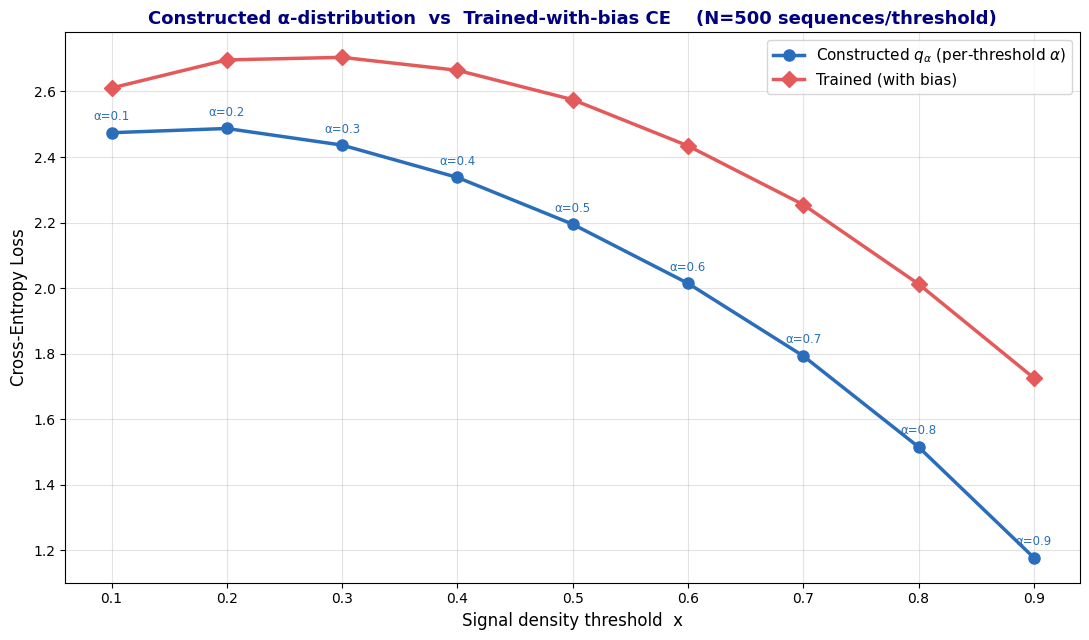

Saved → artifacts_bias/constructed_alpha_vs_trained_ce.png


In [16]:
# ═══════════════════════════════════════════════════════════════════════════════
# CONSTRUCTED α-DISTRIBUTION   vs   TRAINED-WITH-BIAS model
#
# For each threshold x ∈ CONFIG['thresholds'], use a corresponding α to build
# the next-token distribution conditional on the most-recent ruled token r:
#
#       q(y | last_ruled = r) =  α/2          if y ∈ {r^(1), r^(2)}
#                                 0            if y ∈ R \ {r^(1), r^(2)}
#                                 (1-α)/10     if y ∈ N
#
# Generate fresh test sequences and compute CE of q against the true next
# token at every position.  Overlay the trained-with-bias model's CE on the
# SAME sequences for direct comparison.
#
# NOTE.  Setting α = threshold reproduces the true data-generating
# distribution → the resulting CE is the entropy of that distribution
# (the theoretical lower bound any model can achieve).
# ═══════════════════════════════════════════════════════════════════════════════

# ── knobs ────────────────────────────────────────────────────────────────────
ALPHA_PER_THRESH = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]   # one α per threshold; default α=x
                                                # (matches generator → gives entropy)
N_EVAL_SEQS      = 500                           # sequences per threshold

V      = CONFIG['total_vocab']
V_sig  = CONFIG['vocab_set1']
device = CONFIG['device']

assert len(ALPHA_PER_THRESH) == len(CONFIG['thresholds']), \
    f"ALPHA_PER_THRESH must have length {len(CONFIG['thresholds'])}"


# ── generator that ALSO returns each sequence's transition table ─────────────
def generate_with_transitions(num_samples, threshold_x):
    x_data, y_data, trans_list = [], [], []
    for _ in range(num_samples):
        transitions = {i: np.random.choice(V_sig, size=2, replace=False)
                       for i in range(V_sig)}
        seq, last_ruled = [], None
        for _ in range(CONFIG['seq_len'] + 1):
            if np.random.rand() < threshold_x:
                tok = (np.random.randint(0, V_sig) if last_ruled is None
                       else np.random.choice(transitions[last_ruled]))
                last_ruled = tok
            else:
                tok = np.random.randint(V_sig, V)
            seq.append(tok)
        x_data.append(seq[:-1])
        y_data.append(seq[1:])
        trans_list.append(transitions)
    return torch.tensor(x_data), torch.tensor(y_data), trans_list


def constructed_q_per_sequence(x_seq_np, transitions, alpha):
    # Build q[T, V] for one sequence under the α-distribution.
    T = len(x_seq_np)
    q = np.zeros((T, V))
    # Track the most-recent ruled token along the sequence
    cur = -1
    last_ruled_arr = np.empty(T, dtype=int)
    for t in range(T):
        if x_seq_np[t] < V_sig:
            cur = int(x_seq_np[t])
        last_ruled_arr[t] = cur
    for t in range(T):
        lr = last_ruled_arr[t]
        if lr == -1:
            # no ruled token seen yet → α uniform over R, (1-α) uniform over N
            q[t, :V_sig] = alpha     / V_sig
            q[t, V_sig:] = (1 - alpha) / V_sig
        else:
            r1, r2 = transitions[lr]
            q[t, int(r1)]  += alpha / 2.0
            q[t, int(r2)]  += alpha / 2.0
            q[t, V_sig:]    = (1 - alpha) / V_sig
    return q


# ── sweep thresholds ─────────────────────────────────────────────────────────
eps_safe            = 1e-12
constructed_ce_vals = []
trained_ce_vals     = []

for x_thr, alpha in zip(CONFIG['thresholds'], ALPHA_PER_THRESH):
    tx, ty, trans_list = generate_with_transitions(N_EVAL_SEQS, x_thr)

    # ── constructed-distribution CE ──────────────────────────────────────────
    total_ce, total_count = 0.0, 0
    for s in range(N_EVAL_SEQS):
        x_seq = tx[s].numpy()
        y_seq = ty[s].numpy()
        q     = constructed_q_per_sequence(x_seq, trans_list[s], alpha)
        p_t   = np.maximum(q[np.arange(len(y_seq)), y_seq], eps_safe)
        total_ce    += -np.log(p_t).sum()
        total_count += len(y_seq)
    constructed_ce_vals.append(total_ce / total_count)

    # ── trained-with-bias model CE on the SAME sequences ────────────────────
    model_path = os.path.join(CONFIG['artifact_dir'], f"model_x_{x_thr}.pth")
    if os.path.exists(model_path):
        trained = DisentangledTransformer().to(device)
        trained.load_state_dict(torch.load(model_path, map_location=device))
        trained.eval()
        loader = torch.utils.data.DataLoader(
            torch.utils.data.TensorDataset(tx, ty),
            batch_size=CONFIG['batch_size'], shuffle=False)
        tr_sum, tr_cnt = 0.0, 0
        with torch.no_grad():
            for bx, by in loader:
                bx, by = bx.to(device), by.to(device)
                logits = trained(bx)[0].reshape(-1, V)
                tr_sum += F.cross_entropy(logits, by.reshape(-1),
                                          reduction='sum').item()
                tr_cnt += by.numel()
        trained_ce_vals.append(tr_sum / tr_cnt)
        del trained
        if device != 'cpu':
            torch.cuda.empty_cache()
    else:
        trained_ce_vals.append(float('nan'))
        print(f"  WARN: trained checkpoint missing at {model_path}")

    print(f"  x={x_thr:.1f}   α={alpha:.3f}   "
          f"constructed CE = {constructed_ce_vals[-1]:.4f}   "
          f"trained CE = {trained_ce_vals[-1]:.4f}")


# ── plot ─────────────────────────────────────────────────────────────────────
xs = CONFIG['thresholds']
fig, ax = plt.subplots(figsize=(11, 6.5))

ax.plot(xs, constructed_ce_vals, color='#2A6EBB', marker='o',
        lw=2.5, ms=8, label=r'Constructed $q_\alpha$ (per-threshold $\alpha$)')
ax.plot(xs, trained_ce_vals,     color='#E45A5A', marker='D',
        lw=2.5, ms=8, label='Trained (with bias)')

# annotate α value at each constructed point
for xv, cev, a in zip(xs, constructed_ce_vals, ALPHA_PER_THRESH):
    ax.annotate(f'α={a:.2g}', xy=(xv, cev), xytext=(0, 9),
                textcoords='offset points', ha='center', fontsize=8.5,
                color='#2A6EBB')

ax.set_xlabel('Signal density threshold  x', fontsize=12)
ax.set_ylabel('Cross-Entropy Loss',         fontsize=12)
ax.set_title(
    f'Constructed α-distribution  vs  Trained-with-bias CE'
    f'    (N={N_EVAL_SEQS} sequences/threshold)',
    fontsize=13, fontweight='bold', color='navy')
ax.grid(True, alpha=0.35)
ax.legend(fontsize=11, loc='upper right')
plt.tight_layout()
out = f"{CONFIG['output_dir']}/constructed_alpha_vs_trained_ce.png"
plt.savefig(out, dpi=150)
plt.show()
print(f"Saved → {out}")


### Why is $\alpha = x$ (= signal density threshold) the optimal choice?

**Setup.** At any position conditioned on a ruled token $r_t$, the true data-generating distribution $P$ assigns:

$$
P(y \mid r_t) =
\begin{cases}
\tfrac{x}{2}, & y \in \{r_t^{(1)}, r_t^{(2)}\} \\[2pt]
0, & y \in \mathcal{R} \setminus \{r_t^{(1)}, r_t^{(2)}\} \\[2pt]
\tfrac{1-x}{10}, & y \in \mathcal{N}
\end{cases}
$$

The constructed distribution $Q_\alpha$ has the same support pattern but is parameterized by $\alpha$.

**Cross-entropy as a function of $\alpha$.**

$$
\mathrm{CE}(P,\, Q_\alpha)
= -\!\!\sum_{y} P(y)\log Q_\alpha(y)
= -\,x\,\log\!\tfrac{\alpha}{2}\;-\;(1-x)\,\log\!\tfrac{1-\alpha}{10}.
$$

Expand the constants — they do **not** depend on $\alpha$:

$$
\mathrm{CE}(P,\, Q_\alpha) = \underbrace{x\log 2 + (1-x)\log 10}_{\text{constant in }\alpha}
\;-\; x\log\alpha \;-\; (1-x)\log(1-\alpha).
$$

**Minimize.** Differentiate with respect to $\alpha$ and set to zero:

$$
\frac{d}{d\alpha}\mathrm{CE} = -\frac{x}{\alpha} + \frac{1-x}{1-\alpha} = 0
\;\;\Longrightarrow\;\; x(1-\alpha) = \alpha(1-x)
\;\;\Longrightarrow\;\; \boxed{\alpha^{*} = x}.
$$

**Confirm it's a minimum** (not a saddle):

$$
\frac{d^{2}}{d\alpha^{2}}\mathrm{CE} = \frac{x}{\alpha^{2}} + \frac{1-x}{(1-\alpha)^{2}} > 0
\quad \text{for all } \alpha \in (0,1).
$$

Strict convexity in $\alpha$ ⇒ $\alpha^{*} = x$ is the unique global minimizer.

**Resulting (optimal) CE = entropy of $P$:**

$$
\mathrm{CE}(P,\, Q_{x}) = H(P) = x\log 2 + (1-x)\log 10 + H_{\text{bern}}(x),
$$

where $H_{\text{bern}}(x) = -x\log x - (1-x)\log(1-x)$.

**Why this is a hard floor.** This is just Gibbs' inequality applied at every ruled-conditioned position: $\mathrm{CE}(P,\,Q) \ge H(P)$ for any $Q$, with equality iff $Q = P$. Since $Q_{x}$ matches $P$ exactly on this support, **no model — trained, hand-constructed, or otherwise — can beat the blue curve.** The gap between the red (trained) curve and the blue curve is therefore the trained model's **excess KL** $\mathrm{KL}(P\,\|\,Q_{\text{trained}})$.


## cross entropy loss 

### One thing which is clear is the GD trained model is, it's performing far better than our handcoded model especially in the high threshold region. 

But our goal was if we can get a lesser cross entropy loss, 

## No cross-entropy loss as good as the trained model, to validate the hypothesis - indeed my construction is giving near hard predictions. 

So since the model is producing the extremes, and as we have observed that adding logits    
  will make no sense can we becasue after softmax it will cancel out, end up giving the same  
  logits, but can we add a fixed bias after softmax so as to reduce the cross entropy loss    
  further.  

### here is the code. 

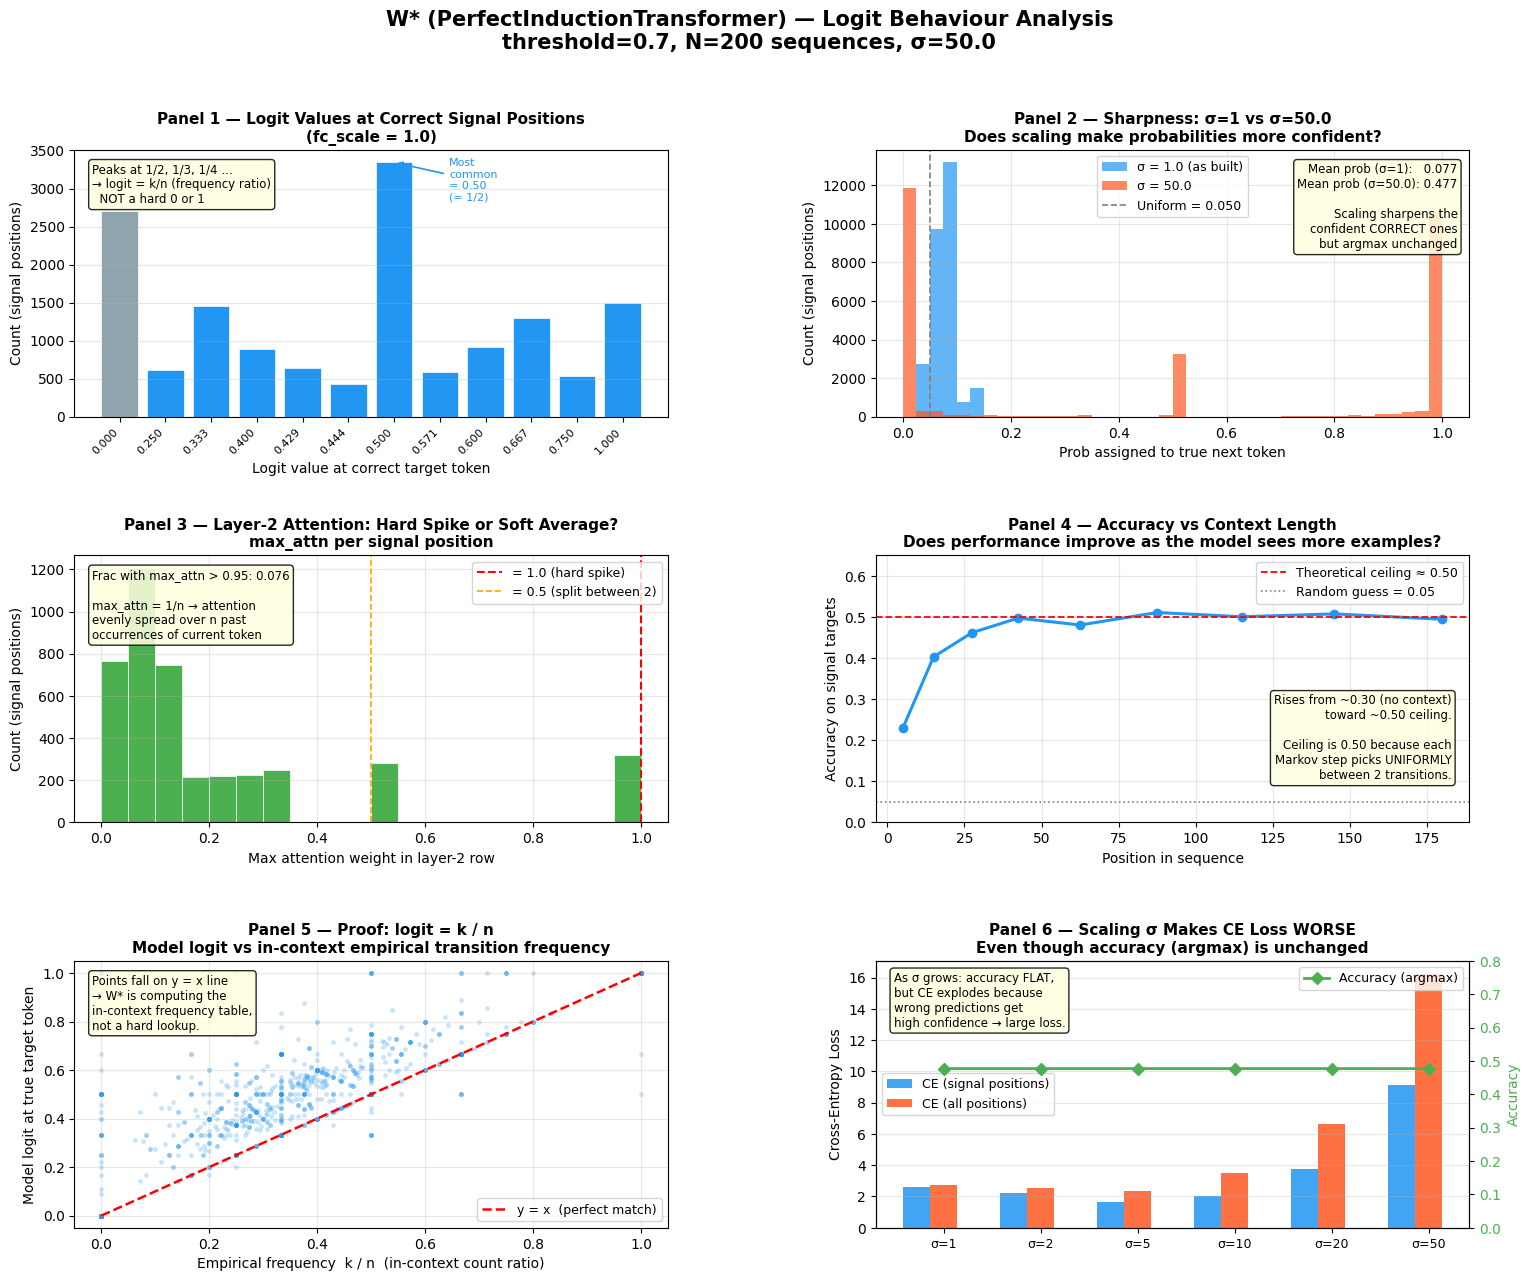

Saved → artifacts_bias/wstar_logit_analysis.png


In [ ]:
# VISUAL EXPLANATION: What does W* actually compute?

# Six panels that build intuition from the bottom up:
#   1. What logit values does W* output at signal positions?
#   2. Does scaling (sigma) make probabilities sharper?
#   3. Is the layer-2 attention a hard spike or a soft average?
#   4. Does accuracy grow as the model sees more context?
#   5. Proof that logit = k/n (empirical frequency)
#   6. Why scaling *hurts* CE loss even though accuracy stays the same

VISUAL_THRESH  = 0.7    # signal density for the demo
SIGMA          = 50.0   # scale factor for comparison
N_VIZ_SEQS    = 200    # sequences to average over

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import torch, torch.nn.functional as F

# ── data + models ─────────────────────────────────────────────────────────────
def _gen(n, thresh, seed=42):
    rng = np.random.RandomState(seed)
    xs, ys = [], []
    for _ in range(n):
        tr = {i: rng.choice(CONFIG['vocab_set1'], size=2, replace=False)
              for i in range(CONFIG['vocab_set1'])}
        seq = []; last = None
        for _ in range(CONFIG['seq_len'] + 1):
            if rng.rand() < thresh:
                tok = rng.randint(0, CONFIG['vocab_set1']) if last is None else rng.choice(tr[last])
                last = tok
            else:
                tok = rng.randint(CONFIG['vocab_set1'], CONFIG['total_vocab'])
            seq.append(tok)
        xs.append(seq[:-1]); ys.append(seq[1:])
    return torch.tensor(xs), torch.tensor(ys)

def _fwd(model, x_seqs):
    model.eval()
    all_lg, all_a2 = [], []
    for s in range(0, len(x_seqs), CONFIG['batch_size']):
        xb = x_seqs[s:s+CONFIG['batch_size']].to(CONFIG['device'])
        with torch.no_grad():
            lg, (_, a2) = model(xb)
        all_lg.append(lg.cpu()); all_a2.append(a2.cpu())
    return torch.cat(all_lg), torch.cat(all_a2)

def _make_wstar(scale=1.0):
    m = PerfectInductionTransformer(query_type='ultimate').to(CONFIG['device'])
    with torch.no_grad():
        m.fc_out.weight.data *= scale
    return m

x_seqs, y_seqs = _gen(N_VIZ_SEQS, VISUAL_THRESH)
m1   = _make_wstar(1.0)
mS   = _make_wstar(SIGMA)

lg1, a2 = _fwd(m1, x_seqs)   # [N,T,V], [N,T,T]
lgS, _  = _fwd(mS, x_seqs)

V       = CONFIG['total_vocab']
is_sig  = y_seqs < CONFIG['vocab_set1']          # [N,T]
tgt_idx = y_seqs.unsqueeze(-1)                    # [N,T,1]

clog1   = lg1.gather(-1, tgt_idx).squeeze(-1)     # [N,T] logit at true token
pr1     = F.softmax(lg1,  dim=-1)
prS     = F.softmax(lgS, dim=-1)
pc1     = pr1.gather(-1, tgt_idx).squeeze(-1)     # prob at true token, scale=1
pcS     = prS.gather(-1, tgt_idx).squeeze(-1)     # prob at true token, scale=sigma

ruled_clog1 = clog1[is_sig].numpy()
ruled_pc1   = pc1[is_sig].numpy()
ruled_pcS   = pcS[is_sig].numpy()


# FIGURE
fig = plt.figure(figsize=(18, 14))
fig.suptitle(
    "W* (PerfectInductionTransformer) — Logit Behaviour Analysis\n"
    f"threshold={VISUAL_THRESH}, N={N_VIZ_SEQS} sequences, σ={SIGMA}",
    fontsize=15, fontweight='bold', y=0.98
)

gs = gridspec.GridSpec(3, 2, figure=fig, hspace=0.52, wspace=0.35)

ACCENT   = '#2196F3'   # blue  — scale=1
ORANGE   = '#FF5722'   # orange — scale=sigma
GREEN    = '#4CAF50'

# ── Panel 1: Logit magnitude histogram ────────────────────────────────────────
ax1 = fig.add_subplot(gs[0, 0])
rounded = np.round(ruled_clog1, 3)
vals, cnts = np.unique(rounded, return_counts=True)
# Only keep top-12 most frequent for readability
order = np.argsort(-cnts)[:12]
top_vals, top_cnts = vals[order], cnts[order]
# Sort by value for the bar chart
sv = np.argsort(top_vals)
top_vals, top_cnts = top_vals[sv], top_cnts[sv]
colors = [ACCENT if v != 0.0 else '#90A4AE' for v in top_vals]
bars = ax1.bar(range(len(top_vals)), top_cnts, color=colors, edgecolor='white', linewidth=0.5)
ax1.set_xticks(range(len(top_vals)))
ax1.set_xticklabels([f"{v:.3f}" for v in top_vals], rotation=45, ha='right', fontsize=8)
ax1.set_xlabel("Logit value at correct target token", fontsize=10)
ax1.set_ylabel("Count (signal positions)", fontsize=10)
ax1.set_title("Panel 1 — Logit Values at Correct Signal Positions\n"
              "(fc_scale = 1.0)", fontsize=11, fontweight='bold')
# Annotate the 0.5 bar (most common)
peak_idx = np.argmax(top_cnts)
ax1.annotate(f"Most\ncommon\n= {top_vals[peak_idx]:.2f}\n(= 1/2)",
             xy=(peak_idx, top_cnts[peak_idx]),
             xytext=(peak_idx + 1.2, top_cnts[peak_idx] * 0.85),
             fontsize=8, color=ACCENT,
             arrowprops=dict(arrowstyle='->', color=ACCENT, lw=1.2))
ax1.text(0.03, 0.95,
         "Peaks at 1/2, 1/3, 1/4 …\n→ logit = k/n (frequency ratio)\n  NOT a hard 0 or 1",
         transform=ax1.transAxes, fontsize=8.5, va='top',
         bbox=dict(boxstyle='round,pad=0.3', fc='lightyellow', alpha=0.85))
ax1.grid(axis='y', alpha=0.3)

# ── Panel 2: Probability at correct token — scale=1 vs scale=sigma ────────────
ax2 = fig.add_subplot(gs[0, 1])
bins = np.linspace(0, 1, 41)
ax2.hist(ruled_pc1, bins=bins, alpha=0.7, color=ACCENT,  label=f"σ = 1.0 (as built)")
ax2.hist(ruled_pcS, bins=bins, alpha=0.7, color=ORANGE, label=f"σ = {SIGMA}")
ax2.axvline(1/V, color='grey', ls='--', lw=1.2, label=f"Uniform = {1/V:.3f}")
ax2.set_xlabel("Prob assigned to true next token", fontsize=10)
ax2.set_ylabel("Count (signal positions)", fontsize=10)
ax2.set_title(f"Panel 2 — Sharpness: σ=1 vs σ={SIGMA}\n"
              "Does scaling make probabilities more confident?", fontsize=11, fontweight='bold')
ax2.legend(fontsize=9)
mean1 = ruled_pc1.mean(); meanS = ruled_pcS.mean()
ax2.text(0.98, 0.95,
         f"Mean prob (σ=1):   {mean1:.3f}\nMean prob (σ={SIGMA}): {meanS:.3f}\n\n"
         f"Scaling sharpens the\nconfident CORRECT ones\nbut argmax unchanged",
         transform=ax2.transAxes, fontsize=8.5, va='top', ha='right',
         bbox=dict(boxstyle='round,pad=0.3', fc='lightyellow', alpha=0.85))
ax2.grid(alpha=0.3)

# ── Panel 3: L2 attention max-weight distribution ─────────────────────────────
ax3 = fig.add_subplot(gs[1, 0])
max_attn, n_attended = [], []
for b in range(min(30, len(x_seqs))):
    for t in range(CONFIG['seq_len']):
        if is_sig[b, t]:
            row = a2[b, t].numpy()
            max_attn.append(row.max())
            n_attended.append((row > 1e-4).sum())
max_attn  = np.array(max_attn)
n_attended = np.array(n_attended)

# Fraction mass plot: how often is max_attn in each bucket?
attn_bins = np.linspace(0, 1, 21)
ax3.hist(max_attn, bins=attn_bins, color=GREEN, edgecolor='white', linewidth=0.5)
ax3.axvline(1.0, color='red', ls='--', lw=1.5, label="= 1.0 (hard spike)")
ax3.axvline(0.5, color='orange', ls='--', lw=1.2, label="= 0.5 (split between 2)")
ax3.set_xlabel("Max attention weight in layer-2 row", fontsize=10)
ax3.set_ylabel("Count (signal positions)", fontsize=10)
ax3.set_title("Panel 3 — Layer-2 Attention: Hard Spike or Soft Average?\n"
              "max_attn per signal position", fontsize=11, fontweight='bold')
ax3.legend(fontsize=9)
frac_hard = (max_attn > 0.95).mean()
ax3.text(0.03, 0.95,
         f"Frac with max_attn > 0.95: {frac_hard:.3f}\n\n"
         "max_attn = 1/n → attention\nevenly spread over n past\n"
         "occurrences of current token",
         transform=ax3.transAxes, fontsize=8.5, va='top',
         bbox=dict(boxstyle='round,pad=0.3', fc='lightyellow', alpha=0.85))
ax3.grid(alpha=0.3)

# ── Panel 4: Accuracy vs sequence position ────────────────────────────────────
ax4 = fig.add_subplot(gs[1, 1])
windows = [(0,10),(10,20),(20,35),(35,50),(50,75),(75,100),(100,130),(130,160),(160,200)]
mid_pts, accs = [], []
for s, e in windows:
    pm = is_sig[:, s:e]
    if pm.sum() == 0: continue
    pt = y_seqs[:, s:e]
    pp = lg1[:, s:e].argmax(-1)
    a  = (pp[pm] == pt[pm]).float().mean().item()
    mid_pts.append((s + e) / 2); accs.append(a)
ax4.plot(mid_pts, accs, marker='o', color=ACCENT, lw=2.2, ms=6)
ax4.axhline(0.5, color='red', ls='--', lw=1.3, label="Theoretical ceiling ≈ 0.50")
ax4.axhline(1/V, color='grey', ls=':', lw=1.2, label=f"Random guess = {1/V:.2f}")
ax4.set_xlabel("Position in sequence", fontsize=10)
ax4.set_ylabel("Accuracy on signal targets", fontsize=10)
ax4.set_title("Panel 4 — Accuracy vs Context Length\n"
              "Does performance improve as the model sees more examples?", fontsize=11, fontweight='bold')
ax4.set_ylim(0, 0.65); ax4.legend(fontsize=9)
ax4.text(0.97, 0.15,
         "Rises from ~0.30 (no context)\ntoward ~0.50 ceiling.\n\n"
         "Ceiling is 0.50 because each\nMarkov step picks UNIFORMLY\n"
         "between 2 transitions.",
         transform=ax4.transAxes, fontsize=8.5, va='bottom', ha='right',
         bbox=dict(boxstyle='round,pad=0.3', fc='lightyellow', alpha=0.85))
ax4.grid(alpha=0.3)

# ── Panel 5: logit = k/n proof ────────────────────────────────────────────────
ax5 = fig.add_subplot(gs[2, 0])
# For each signal position where input is signal, compute empirical k/n
emp_freq, model_logit = [], []
x_np = x_seqs.numpy(); y_np = y_seqs.numpy()
lg1_np = lg1.numpy()
for b in range(min(10, N_VIZ_SEQS)):       # 10 sequences is enough for the plot
    sig_hist = []                           # (position, token) of past signal tokens
    for t in range(CONFIG['seq_len']):
        x_t = int(x_np[b, t]); y_t = int(y_np[b, t])
        is_sig_input  = (x_t < CONFIG['vocab_set1'])
        is_sig_target = (y_t < CONFIG['vocab_set1'])
        if is_sig_input and is_sig_target and len(sig_hist) >= 2:
            # count how often x_t → y_t in the history
            n_x  = sum(1 for (tok, nxt) in sig_hist if tok == x_t)
            n_xy = sum(1 for (tok, nxt) in sig_hist if tok == x_t and nxt == y_t)
            if n_x > 0:
                emp_freq.append(n_xy / n_x)
                model_logit.append(float(lg1_np[b, t, y_t]))
        if is_sig_input:
            sig_hist.append((x_t, y_t))
emp_freq    = np.array(emp_freq)
model_logit = np.array(model_logit)
ax5.scatter(emp_freq, model_logit, alpha=0.25, s=12, color=ACCENT, linewidths=0)
diag = np.linspace(0, 1, 50)
ax5.plot(diag, diag, 'r--', lw=1.8, label="y = x  (perfect match)")
ax5.set_xlabel("Empirical frequency  k / n  (in-context count ratio)", fontsize=10)
ax5.set_ylabel("Model logit at true target token", fontsize=10)
ax5.set_title("Panel 5 — Proof: logit = k / n\n"
              "Model logit vs in-context empirical transition frequency", fontsize=11, fontweight='bold')
ax5.legend(fontsize=9)
ax5.text(0.03, 0.95,
         "Points fall on y = x line\n→ W* is computing the\nin-context frequency table,\n"
         "not a hard lookup.",
         transform=ax5.transAxes, fontsize=8.5, va='top',
         bbox=dict(boxstyle='round,pad=0.3', fc='lightyellow', alpha=0.85))
ax5.grid(alpha=0.3)

# ── Panel 6: CE loss — scaling hurts ─────────────────────────────────────────
ax6 = fig.add_subplot(gs[2, 1])
sigmas = [1, 2, 5, 10, 20, 50]
ce_sig_vals = []; ce_all_vals = []; acc_vals = []
for sig in sigmas:
    mTmp = _make_wstar(float(sig))
    lgTmp, _ = _fwd(mTmp, x_seqs)
    ce_sig_vals.append(F.cross_entropy(lgTmp[is_sig], y_seqs[is_sig]).item())
    ce_all_vals.append(F.cross_entropy(lgTmp.reshape(-1, V), y_seqs.reshape(-1)).item())
    acc_vals.append((lgTmp.argmax(-1)[is_sig] == y_seqs[is_sig]).float().mean().item())

x_pos = np.arange(len(sigmas))
w = 0.28
bars1 = ax6.bar(x_pos - w,   ce_sig_vals, w, label='CE (signal positions)', color=ACCENT,  alpha=0.85)
bars2 = ax6.bar(x_pos,       ce_all_vals, w, label='CE (all positions)',    color=ORANGE, alpha=0.85)
ax6.set_xticks(x_pos)
ax6.set_xticklabels([f"σ={s}" for s in sigmas], fontsize=9)
ax6.set_ylabel("Cross-Entropy Loss", fontsize=10)
ax6.set_title("Panel 6 — Scaling σ Makes CE Loss WORSE\n"
              "Even though accuracy (argmax) is unchanged", fontsize=11, fontweight='bold')
ax6.legend(fontsize=9)
# Overlay accuracy line on secondary axis
ax6b = ax6.twinx()
ax6b.plot(x_pos, acc_vals, marker='D', color=GREEN, lw=2, ms=6, label='Accuracy (argmax)')
ax6b.set_ylabel("Accuracy", fontsize=10, color=GREEN)
ax6b.tick_params(axis='y', labelcolor=GREEN)
ax6b.set_ylim(0, 0.8); ax6b.legend(loc='upper right', fontsize=9)
ax6.text(0.03, 0.96,
         "As σ grows: accuracy FLAT,\nbut CE explodes because\nwrong predictions get\nhigh confidence → large loss.",
         transform=ax6.transAxes, fontsize=8.5, va='top',
         bbox=dict(boxstyle='round,pad=0.3', fc='lightyellow', alpha=0.85))
ax6.grid(axis='y', alpha=0.3)

save_path = f"{CONFIG['output_dir']}/wstar_logit_analysis.png"
plt.savefig(save_path, dpi=130, bbox_inches='tight')
plt.show()
print(f"Saved → {save_path}")


Signal positions: 20997
  Correct (argmax=target): 10100 (48.1%)
  Wrong   (argmax≠target): 10897 (51.9%)
Noise positions: 9003


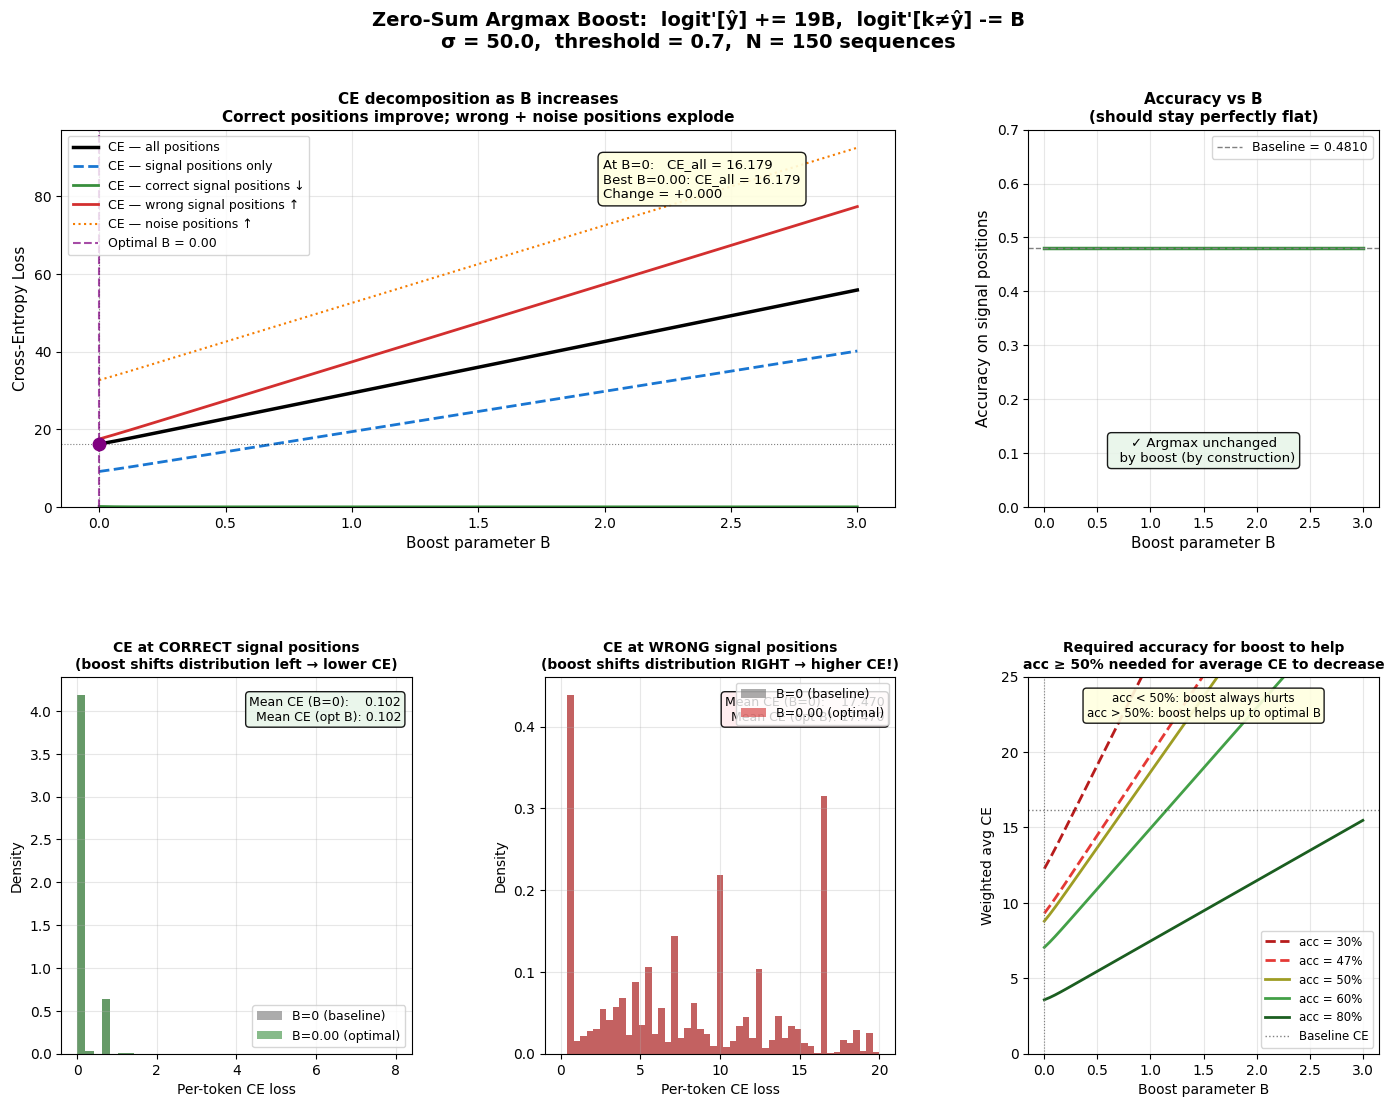


Saved → artifacts_bias/zero_sum_boost_sigma50.0.png

Conclusion:
  Boost REDUCES CE at correct positions  (gain per correct token: +0.000)
  Boost INCREASES CE at wrong  positions  (cost per wrong   token: +0.000)
  With accuracy = 48.1%, wrong positions dominate → net CE change = +0.000
  You need accuracy > 50% for the boost to help on average.


In [ ]:


# ═══════════════════════════════════════════════════════════════════════════════
# ZERO-SUM ARGMAX BOOST — Does it reduce CE?
# ═══════════════════════════════════════════════════════════════════════════════


# Idea (user proposal): after sigma-scaling, apply a zero-sum logit shift:
#
#   logit'[ŷ]   +=  19 * B        ← boost the argmax (predicted) token
#   logit'[k≠ŷ] -=   B           ← penalise all 19 other tokens
#   ────────────────────────────────────────────────────
#   Net sum of changes = 19B − 19B = 0   (zero-sum ✓)
#   Accuracy: unchanged (argmax is the same token as before)

# Key question: does this reduce average CE?

# Answer: ONLY when the model's prediction is correct.
#   - Correct position  → CE goes DOWN  (boost helps)
#   - Wrong   position  → CE goes UP    (boost hurts)

# So the net effect depends entirely on accuracy.
# With W* accuracy ≈ 47-50%, wrong positions dominate → overall CE worsens.


# ── Config ───────────────────────────────────────────────────────────────────
BOOST_SIGMA  = 50.0    # sigma for logit scaling (try 10, 50, 100)
B_VALUES     = [round(v, 3) for v in __import__('numpy').linspace(0, 3.0, 50)]
BOOST_THRESH = 0.7     # signal density threshold
N_BOOST_SEQS = 150     # sequences for statistics


import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import torch, torch.nn.functional as F


# ── helpers ───────────────────────────────────────────────────────────────────
def _gen_boost(n, thresh, seed=0):
    rng = np.random.RandomState(seed)
    xs, ys = [], []
    for _ in range(n):
        tr = {i: rng.choice(CONFIG['vocab_set1'], size=2, replace=False)
              for i in range(CONFIG['vocab_set1'])}
        seq = []; last = None
        for _ in range(CONFIG['seq_len'] + 1):
            if rng.rand() < thresh:
                tok = rng.randint(0, CONFIG['vocab_set1']) if last is None else rng.choice(tr[last])
                last = tok
            else:
                tok = rng.randint(CONFIG['vocab_set1'], CONFIG['total_vocab'])
            seq.append(tok)
        xs.append(seq[:-1]); ys.append(seq[1:])
    return torch.tensor(xs), torch.tensor(ys)


def _fwd_boost(model, x_seqs):
    model.eval()
    all_lg = []
    for s in range(0, len(x_seqs), CONFIG['batch_size']):
        xb = x_seqs[s:s+CONFIG['batch_size']].to(CONFIG['device'])
        with torch.no_grad():
            lg, _ = model(xb)
        all_lg.append(lg.cpu())
    return torch.cat(all_lg)                   # [N, T, V]


def apply_zero_sum_boost(logits_scaled, B):
    """logits_scaled: [N,T,V]. Add 19B to argmax, subtract B from all others."""
    adj = logits_scaled - B                    # subtract B from everyone
    argmax_idx = logits_scaled.argmax(dim=-1, keepdim=True)  # [N,T,1]
    adj.scatter_(-1, argmax_idx,
                 adj.gather(-1, argmax_idx) + 20 * B)        # argmax net = +19B
    return adj


# ── run model ─────────────────────────────────────────────────────────────────
m_sigma = PerfectInductionTransformer(query_type='ultimate').to(CONFIG['device'])
with torch.no_grad():
    m_sigma.fc_out.weight.data *= BOOST_SIGMA

x_seqs, y_seqs = _gen_boost(N_BOOST_SEQS, BOOST_THRESH)
logits_scaled   = _fwd_boost(m_sigma, x_seqs)       # [N, T, V]

V        = CONFIG['total_vocab']
is_sig   = y_seqs < CONFIG['vocab_set1']
tgt_idx  = y_seqs.unsqueeze(-1)

# Pre-compute argmax mask (same for all B, since boost preserves argmax)
argmax   = logits_scaled.argmax(dim=-1)               # [N, T]
is_correct = (argmax == y_seqs) & is_sig              # signal AND correct
is_wrong   = (argmax != y_seqs) & is_sig              # signal AND wrong
is_noise   = ~is_sig                                  # noise positions

print(f"Signal positions: {is_sig.sum().item()}")
print(f"  Correct (argmax=target): {is_correct.sum().item()} "
      f"({100*is_correct.sum()/is_sig.sum():.1f}%)")
print(f"  Wrong   (argmax≠target): {is_wrong.sum().item()} "
      f"({100*is_wrong.sum()/is_sig.sum():.1f}%)")
print(f"Noise positions: {is_noise.sum().item()}")

# ── sweep B ───────────────────────────────────────────────────────────────────
rec = {'B': [], 'ce_all': [], 'ce_sig': [],
       'ce_correct': [], 'ce_wrong': [], 'ce_noise': [],
       'acc': []}

for B in B_VALUES:
    adj = apply_zero_sum_boost(logits_scaled, B)
    tgt_flat = y_seqs.reshape(-1)
    adj_flat  = adj.reshape(-1, V)

    ce_all = F.cross_entropy(adj_flat, tgt_flat).item()
    ce_sig = F.cross_entropy(adj[is_sig],     y_seqs[is_sig]).item()     if is_correct.sum() > 0 else float('nan')
    ce_cor = F.cross_entropy(adj[is_correct], y_seqs[is_correct]).item() if is_correct.sum() > 0 else float('nan')
    ce_wrg = F.cross_entropy(adj[is_wrong],   y_seqs[is_wrong]).item()   if is_wrong.sum()   > 0 else float('nan')
    ce_nse = F.cross_entropy(adj[is_noise],   y_seqs[is_noise]).item()   if is_noise.sum()   > 0 else float('nan')
    acc    = (adj.argmax(-1)[is_sig] == y_seqs[is_sig]).float().mean().item()

    rec['B'].append(B); rec['ce_all'].append(ce_all); rec['ce_sig'].append(ce_sig)
    rec['ce_correct'].append(ce_cor); rec['ce_wrong'].append(ce_wrg)
    rec['ce_noise'].append(ce_nse);   rec['acc'].append(acc)

B_arr   = np.array(rec['B'])
ce_all  = np.array(rec['ce_all'])
ce_sig  = np.array(rec['ce_sig'])
ce_cor  = np.array(rec['ce_correct'])
ce_wrg  = np.array(rec['ce_wrong'])
ce_nse  = np.array(rec['ce_noise'])
acc_arr = np.array(rec['acc'])

# ── figure ────────────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(17, 12))
fig.suptitle(
    f"Zero-Sum Argmax Boost:  logit'[ŷ] += 19B,  logit'[k≠ŷ] -= B\n"
    f"σ = {BOOST_SIGMA},  threshold = {BOOST_THRESH},  N = {N_BOOST_SEQS} sequences",
    fontsize=14, fontweight='bold', y=0.98
)
gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.45, wspace=0.38)

BLUE   = '#1976D2'
RED    = '#D32F2F'
GREEN  = '#388E3C'
ORANGE = '#F57C00'
GREY   = '#757575'

# ── Panel 1: CE decomposition ─────────────────────────────────────────────────
ax1 = fig.add_subplot(gs[0, :2])    # wide panel
ax1.plot(B_arr, ce_all,  color='black',  lw=2.5, label='CE — all positions', zorder=5)
ax1.plot(B_arr, ce_sig,  color=BLUE,     lw=2.0, ls='--', label='CE — signal positions only')
ax1.plot(B_arr, ce_cor,  color=GREEN,    lw=2.0, label='CE — correct signal positions ↓')
ax1.plot(B_arr, ce_wrg,  color=RED,      lw=2.0, label='CE — wrong signal positions ↑')
ax1.plot(B_arr, ce_nse,  color=ORANGE,   lw=1.5, ls=':', label='CE — noise positions ↑')

ax1.axvline(0, color='grey', lw=0.8, ls=':')
ax1.axhline(ce_all[0], color='black', lw=0.8, ls=':', alpha=0.5)

best_B_idx = np.argmin(ce_all)
best_B     = B_arr[best_B_idx]
ax1.axvline(best_B, color='purple', lw=1.5, ls='--', alpha=0.7, label=f'Optimal B = {best_B:.2f}')
ax1.scatter([best_B], [ce_all[best_B_idx]], color='purple', zorder=6, s=80)

ax1.set_xlabel("Boost parameter B", fontsize=11)
ax1.set_ylabel("Cross-Entropy Loss", fontsize=11)
ax1.set_title("CE decomposition as B increases\n"
              "Correct positions improve; wrong + noise positions explode", fontsize=11, fontweight='bold')
ax1.legend(fontsize=9, loc='upper left')
ax1.set_ylim(bottom=0)
ax1.grid(alpha=0.3)
ax1.text(0.65, 0.82,
         f"At B=0:   CE_all = {ce_all[0]:.3f}\n"
         f"Best B={best_B:.2f}: CE_all = {ce_all[best_B_idx]:.3f}\n"
         f"Change = {ce_all[best_B_idx]-ce_all[0]:+.3f}",
         transform=ax1.transAxes, fontsize=9.5,
         bbox=dict(boxstyle='round,pad=0.4', fc='lightyellow', alpha=0.9))

# ── Panel 2: Accuracy flat ────────────────────────────────────────────────────
ax2 = fig.add_subplot(gs[0, 2])
ax2.plot(B_arr, acc_arr, color=GREEN, lw=2.5)
ax2.axhline(acc_arr[0], color='grey', lw=1, ls='--', label=f'Baseline = {acc_arr[0]:.4f}')
ax2.set_xlabel("Boost parameter B", fontsize=11)
ax2.set_ylabel("Accuracy on signal positions", fontsize=11)
ax2.set_title("Accuracy vs B\n(should stay perfectly flat)", fontsize=11, fontweight='bold')
ax2.set_ylim(0, 0.7)
ax2.legend(fontsize=9)
ax2.grid(alpha=0.3)
ax2.text(0.5, 0.12,
         "✓ Argmax unchanged\n  by boost (by construction)",
         transform=ax2.transAxes, fontsize=9.5, ha='center',
         bbox=dict(boxstyle='round,pad=0.3', fc='#E8F5E9', alpha=0.9))

# ── Panel 3: CE correct vs wrong at fixed B=1 ────────────────────────────────
ax3 = fig.add_subplot(gs[1, 0])
# Distribution of per-token CE at B=0 and B=best_B
adj_b0   = apply_zero_sum_boost(logits_scaled, 0.0)
adj_best = apply_zero_sum_boost(logits_scaled, best_B)

def per_token_ce(adj, mask, tgt):
    """Per-token CE at masked positions."""
    with torch.no_grad():
        log_p = F.log_softmax(adj[mask], dim=-1)
        return -log_p[torch.arange(mask.sum()), tgt[mask]]

ce_cor_b0   = per_token_ce(adj_b0,   is_correct, y_seqs).numpy()
ce_cor_best = per_token_ce(adj_best, is_correct, y_seqs).numpy()

bins = np.linspace(0, 8, 40)
ax3.hist(ce_cor_b0,   bins=bins, alpha=0.6, color=GREY,  label=f'B=0 (baseline)', density=True)
ax3.hist(ce_cor_best, bins=bins, alpha=0.6, color=GREEN, label=f'B={best_B:.2f} (optimal)', density=True)
ax3.set_xlabel("Per-token CE loss", fontsize=10)
ax3.set_ylabel("Density", fontsize=10)
ax3.set_title("CE at CORRECT signal positions\n(boost shifts distribution left → lower CE)", fontsize=10, fontweight='bold')
ax3.legend(fontsize=9)
ax3.grid(alpha=0.3)
ax3.text(0.97, 0.95,
         f"Mean CE (B=0):    {ce_cor_b0.mean():.3f}\nMean CE (opt B): {ce_cor_best.mean():.3f}",
         transform=ax3.transAxes, fontsize=9, va='top', ha='right',
         bbox=dict(boxstyle='round,pad=0.3', fc='#E8F5E9', alpha=0.9))

# ── Panel 4: CE at wrong positions ────────────────────────────────────────────
ax4 = fig.add_subplot(gs[1, 1])
ce_wrg_b0   = per_token_ce(adj_b0,   is_wrong, y_seqs).numpy()
ce_wrg_best = per_token_ce(adj_best, is_wrong, y_seqs).numpy()

bins_w = np.linspace(0, 20, 50)
ax4.hist(ce_wrg_b0,   bins=bins_w, alpha=0.6, color=GREY,  label=f'B=0 (baseline)', density=True)
ax4.hist(ce_wrg_best, bins=bins_w, alpha=0.6, color=RED,   label=f'B={best_B:.2f} (optimal)', density=True)
ax4.set_xlabel("Per-token CE loss", fontsize=10)
ax4.set_ylabel("Density", fontsize=10)
ax4.set_title("CE at WRONG signal positions\n(boost shifts distribution RIGHT → higher CE!)", fontsize=10, fontweight='bold')
ax4.legend(fontsize=9)
ax4.grid(alpha=0.3)
ax4.text(0.97, 0.95,
         f"Mean CE (B=0):    {ce_wrg_b0.mean():.3f}\nMean CE (opt B): {ce_wrg_best.mean():.3f}",
         transform=ax4.transAxes, fontsize=9, va='top', ha='right',
         bbox=dict(boxstyle='round,pad=0.3', fc='#FFEBEE', alpha=0.9))

# ── Panel 5: "What accuracy do you need for the boost to help?" ───────────────
ax5 = fig.add_subplot(gs[1, 2])
# Theoretical: avg CE = acc * CE_correct(B) + (1-acc) * CE_wrong(B)
# Simulate this for different accuracy levels
B_th   = np.linspace(0, 3, 60)
accs_th = [0.30, 0.47, 0.50, 0.60, 0.80]
colors_th = ['#B71C1C', '#E53935', '#9E9D24', '#43A047', '#1B5E20']
for a_th, col in zip(accs_th, colors_th):
    # Use empirical CE_correct and CE_wrong shapes, scaled to acc
    ce_cor_th = np.interp(B_th, B_arr, ce_cor)
    ce_wrg_th = np.interp(B_th, B_arr, ce_wrg)
    avg_th = a_th * ce_cor_th + (1 - a_th) * ce_wrg_th
    ax5.plot(B_th, avg_th, color=col, lw=2,
             label=f'acc = {a_th:.0%}',
             ls='-' if a_th >= 0.50 else '--')
ax5.axhline(ce_all[0], color='black', lw=1, ls=':', alpha=0.5, label='Baseline CE')
ax5.axvline(0, color='grey', lw=0.8, ls=':')
ax5.set_xlabel("Boost parameter B", fontsize=10)
ax5.set_ylabel("Weighted avg CE", fontsize=10)
ax5.set_title("Required accuracy for boost to help\n"
              "acc ≥ 50% needed for average CE to decrease", fontsize=10, fontweight='bold')
ax5.legend(fontsize=8.5)
ax5.set_ylim(bottom=0, top=min(ce_all[0]*4, 25))
ax5.grid(alpha=0.3)
ax5.text(0.5, 0.96,
         "acc < 50%: boost always hurts\nacc > 50%: boost helps up to optimal B",
         transform=ax5.transAxes, fontsize=8.5, ha='center', va='top',
         bbox=dict(boxstyle='round,pad=0.3', fc='lightyellow', alpha=0.9))

save_path = f"{CONFIG['output_dir']}/zero_sum_boost_sigma{BOOST_SIGMA}.png"
plt.savefig(save_path, dpi=130, bbox_inches='tight')
plt.show()
  
print(f"\nSaved → {save_path}")
print(f"\nConclusion:")
print(f"  Boost REDUCES CE at correct positions  (gain per correct token: {ce_cor[0]-ce_cor[best_B_idx]:+.3f})")
print(f"  Boost INCREASES CE at wrong  positions  (cost per wrong   token: {ce_wrg[best_B_idx]-ce_wrg[0]:+.3f})")
print(f"  With accuracy = {acc_arr[0]:.1%}, wrong positions dominate → net CE change = {ce_all[best_B_idx]-ce_all[0]:+.3f}")
print(f"  You need accuracy > 50% for the boost to help on average.")


Baseline CE (B=0):          16.1184
Optimal  CE (B=10.00): 10.1987
Improvement:                +5.9197
Theoretical floor (signal): 0.6931
Theoretical floor (noise):  2.3026
Mixed floor (thresh=0.7):    1.1707


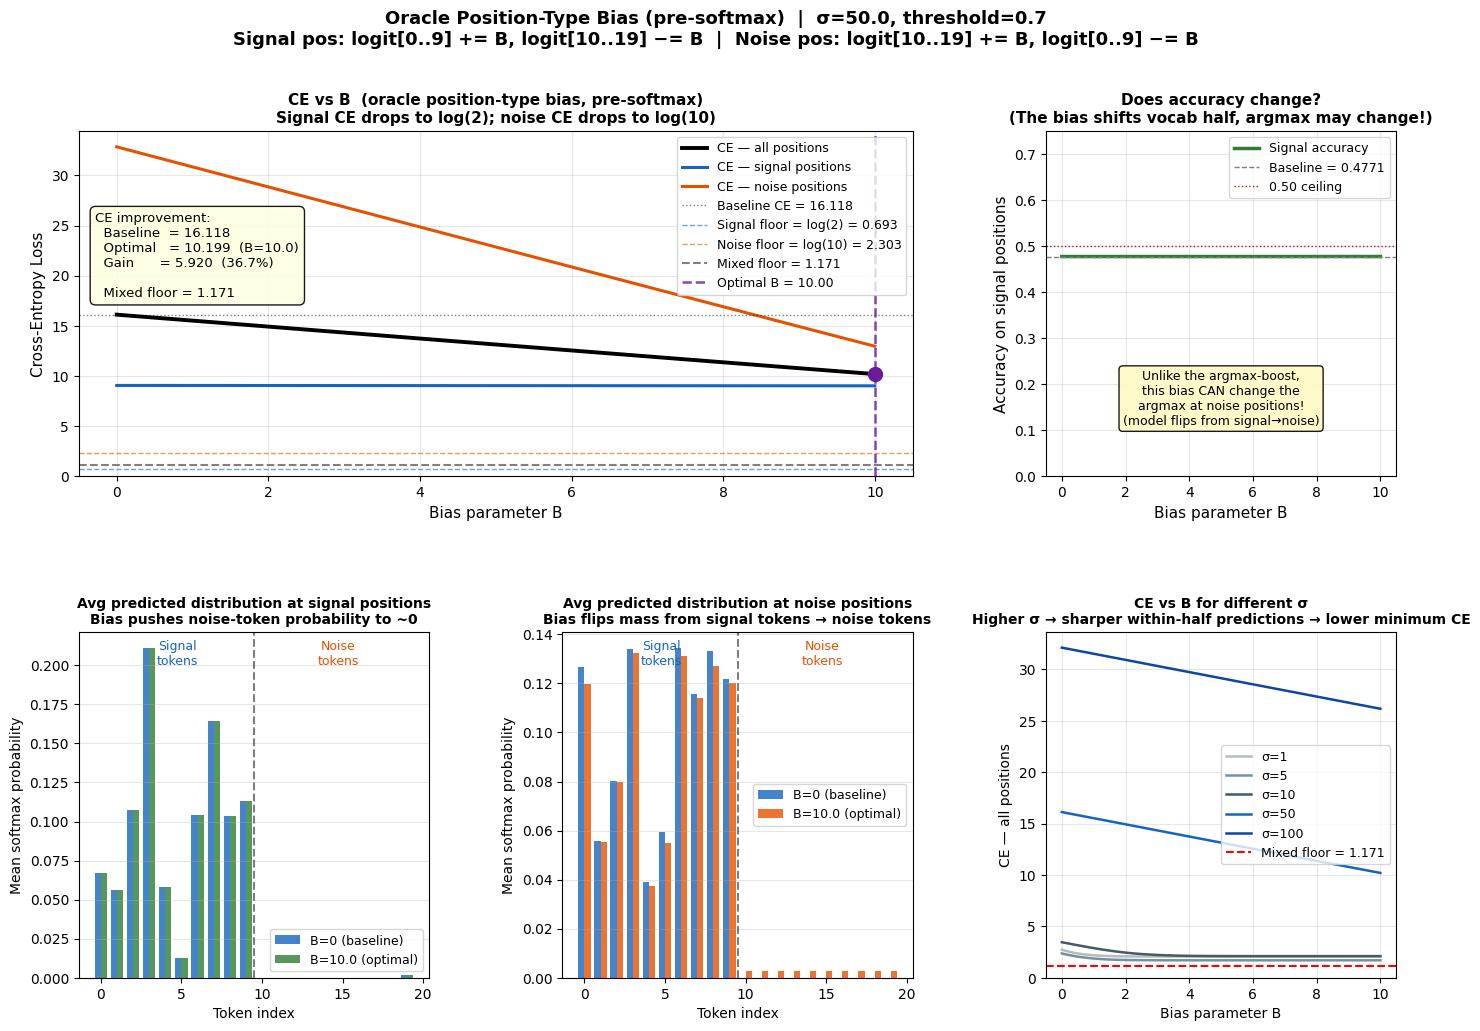


Saved → artifacts_bias/oracle_bias_sigma50.0.png


In [4]:

# ═══════════════════════════════════════════════════════════════════════════════
# ORACLE POSITION-TYPE BIAS  (pre-softmax)
# ═══════════════════════════════════════════════════════════════════════════════
#
# Idea:  after sigma-scaling, add a fixed bias to the logits BEFORE softmax
#        that pushes the model into the correct vocabulary half:
#
#   Signal position  → logit[0..9]  += B,  logit[10..19] -= B
#   Noise  position  → logit[10..19]+= B,  logit[0..9]   -= B
#
# "Oracle" means we use ground-truth labels to know the position type.
# This gives the UPPER BOUND on CE achievable with this strategy.
#
# Why this works:
#   • High σ sharpens the model's prediction *within* each vocab half
#   • The bias B separates the two halves cleanly
#   • At signal positions: noise tokens (which W* assigns ~0 logit anyway)
#     get pushed further down, reducing denominator noise in CE
#   • At noise positions: signal tokens get suppressed; uniform mass over
#     10 noise tokens → best possible CE = log(10) ≈ 2.30
#
# ── Config ───────────────────────────────────────────────────────────────────
ORACLE_SIGMA  = 50.0    # sigma for initial logit scaling
B_SWEEP       = list(__import__('numpy').linspace(0, 10, 80))
ORACLE_THRESH = 0.7     # signal density threshold
N_ORACLE_SEQS = 200     # sequences

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import torch, torch.nn.functional as F

V_SIG = CONFIG['vocab_set1']            # 10  — signal tokens  0..9
V_ALL = CONFIG['total_vocab']           # 20

# ── helpers ───────────────────────────────────────────────────────────────────
def _gen_oracle(n, thresh, seed=1):
    rng = np.random.RandomState(seed)
    xs, ys = [], []
    for _ in range(n):
        tr = {i: rng.choice(V_SIG, size=2, replace=False) for i in range(V_SIG)}
        seq = []; last = None
        for _ in range(CONFIG['seq_len'] + 1):
            if rng.rand() < thresh:
                tok = rng.randint(0, V_SIG) if last is None else rng.choice(tr[last])
                last = tok
            else:
                tok = rng.randint(V_SIG, V_ALL)
            seq.append(tok)
        xs.append(seq[:-1]); ys.append(seq[1:])
    return torch.tensor(xs), torch.tensor(ys)

def _fwd_oracle(model, x_seqs):
    model.eval()
    parts = []
    for s in range(0, len(x_seqs), CONFIG['batch_size']):
        xb = x_seqs[s:s+CONFIG['batch_size']].to(CONFIG['device'])
        with torch.no_grad():
            lg, _ = model(xb)
        parts.append(lg.cpu())
    return torch.cat(parts)                     # [N, T, V]

def apply_oracle_bias(logits_scaled, is_signal_mask, B):
    """
    logits_scaled : [N, T, V]
    is_signal_mask: [N, T] bool — True where target is a signal token
    B             : float
    Returns adjusted logits [N, T, V] with pre-softmax bias applied.
    """
    # Build per-position bias vectors and add — avoids boolean+slice indexing issues
    import torch as _torch
    sig_vec = _torch.zeros(V_ALL)
    sig_vec[:V_SIG]  =  B     # signal tokens  +B
    sig_vec[V_SIG:]  = -B     # noise tokens   -B

    nse_vec = _torch.zeros(V_ALL)
    nse_vec[:V_SIG]  = -B     # signal tokens  -B
    nse_vec[V_SIG:]  =  B     # noise tokens   +B

    sig = is_signal_mask          # [N, T]
    adj = logits_scaled.clone()   # [N, T, V]

    # adj[sig] is [N_sig, V] — broadcast add the 1-D bias vector
    adj[sig]  = adj[sig]  + sig_vec
    adj[~sig] = adj[~sig] + nse_vec

    return adj

# ── build model & run ─────────────────────────────────────────────────────────
m_oracle = PerfectInductionTransformer(query_type='ultimate').to(CONFIG['device'])
with torch.no_grad():
    m_oracle.fc_out.weight.data *= ORACLE_SIGMA

x_seqs, y_seqs = _gen_oracle(N_ORACLE_SEQS, ORACLE_THRESH)
logits_scaled   = _fwd_oracle(m_oracle, x_seqs)       # [N, T, V]

is_sig  = y_seqs < V_SIG                              # oracle signal mask
is_nse  = ~is_sig

tgt_flat = y_seqs.reshape(-1)

# Theoretical CE floors
ce_floor_signal = np.log(2)     # best possible if 50% accuracy, 2-choice Markov
ce_floor_noise  = np.log(10)    # best possible at noise positions (uniform over 10)

# ── sweep B ───────────────────────────────────────────────────────────────────
rec = {k: [] for k in ['B','ce_all','ce_sig','ce_nse','acc_sig']}
for B in B_SWEEP:
    adj  = apply_oracle_bias(logits_scaled, is_sig, B)
    ce_all = F.cross_entropy(adj.reshape(-1, V_ALL), tgt_flat).item()
    ce_sig = F.cross_entropy(adj[is_sig], y_seqs[is_sig]).item()
    ce_nse = F.cross_entropy(adj[is_nse], y_seqs[is_nse]).item()
    acc    = (adj.argmax(-1)[is_sig] == y_seqs[is_sig]).float().mean().item()
    rec['B'].append(B); rec['ce_all'].append(ce_all)
    rec['ce_sig'].append(ce_sig); rec['ce_nse'].append(ce_nse)
    rec['acc_sig'].append(acc)

B_arr    = np.array(rec['B'])
ce_all   = np.array(rec['ce_all'])
ce_sig   = np.array(rec['ce_sig'])
ce_nse   = np.array(rec['ce_nse'])
acc_arr  = np.array(rec['acc_sig'])

opt_idx  = np.argmin(ce_all)
opt_B    = B_arr[opt_idx]
opt_CE   = ce_all[opt_idx]
base_CE  = ce_all[0]

print(f"Baseline CE (B=0):          {base_CE:.4f}")
print(f"Optimal  CE (B={opt_B:.2f}): {opt_CE:.4f}")
print(f"Improvement:                {base_CE - opt_CE:+.4f}")
print(f"Theoretical floor (signal): {ce_floor_signal:.4f}")
print(f"Theoretical floor (noise):  {ce_floor_noise:.4f}")
frac_sig = is_sig.float().mean().item()
frac_nse = 1 - frac_sig
mixed_floor = frac_sig * ce_floor_signal + frac_nse * ce_floor_noise
print(f"Mixed floor (thresh={ORACLE_THRESH}):    {mixed_floor:.4f}")

# ── figure ────────────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(17, 11))
fig.suptitle(
    f"Oracle Position-Type Bias (pre-softmax)  |  σ={ORACLE_SIGMA}, threshold={ORACLE_THRESH}\n"
    r"Signal pos: logit[0..9] += B, logit[10..19] −= B  |  "
    r"Noise pos: logit[10..19] += B, logit[0..9] −= B",
    fontsize=13, fontweight='bold', y=0.99
)
gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.45, wspace=0.38)

BLUE   = '#1565C0'
RED    = '#B71C1C'
GREEN  = '#2E7D32'
ORANGE = '#E65100'
PURPLE = '#6A1B9A'

# ── Panel 1: main CE vs B ─────────────────────────────────────────────────────
ax1 = fig.add_subplot(gs[0, :2])
ax1.plot(B_arr, ce_all,  color='black',  lw=2.8, label='CE — all positions', zorder=5)
ax1.plot(B_arr, ce_sig,  color=BLUE,     lw=2.2, label='CE — signal positions')
ax1.plot(B_arr, ce_nse,  color=ORANGE,   lw=2.2, label='CE — noise positions')

ax1.axhline(base_CE,         color='black',  lw=1, ls=':', alpha=0.5, label=f'Baseline CE = {base_CE:.3f}')
ax1.axhline(ce_floor_signal, color=BLUE,     lw=1, ls='--', alpha=0.6, label=f'Signal floor = log(2) = {ce_floor_signal:.3f}')
ax1.axhline(ce_floor_noise,  color=ORANGE,   lw=1, ls='--', alpha=0.6, label=f'Noise floor = log(10) = {ce_floor_noise:.3f}')
ax1.axhline(mixed_floor,     color='grey',   lw=1.5, ls='--', label=f'Mixed floor = {mixed_floor:.3f}')
ax1.axvline(opt_B, color=PURPLE, lw=1.8, ls='--', alpha=0.8, label=f'Optimal B = {opt_B:.2f}')
ax1.scatter([opt_B], [opt_CE], color=PURPLE, zorder=6, s=100)

ax1.set_xlabel("Bias parameter B", fontsize=11)
ax1.set_ylabel("Cross-Entropy Loss", fontsize=11)
ax1.set_title("CE vs B  (oracle position-type bias, pre-softmax)\n"
              "Signal CE drops to log(2); noise CE drops to log(10)", fontsize=11, fontweight='bold')
ax1.legend(fontsize=9, loc='upper right')
ax1.set_ylim(bottom=0)
ax1.grid(alpha=0.3)
ax1.text(0.02, 0.52,
         f"CE improvement:\n"
         f"  Baseline  = {base_CE:.3f}\n"
         f"  Optimal   = {opt_CE:.3f}  (B={opt_B:.1f})\n"
         f"  Gain      = {base_CE-opt_CE:.3f}  ({100*(base_CE-opt_CE)/base_CE:.1f}%)\n\n"
         f"  Mixed floor = {mixed_floor:.3f}",
         transform=ax1.transAxes, fontsize=9.5,
         bbox=dict(boxstyle='round,pad=0.4', fc='lightyellow', alpha=0.9))

# ── Panel 2: accuracy — does it stay or change? ───────────────────────────────
ax2 = fig.add_subplot(gs[0, 2])
ax2.plot(B_arr, acc_arr, color=GREEN, lw=2.5, label='Signal accuracy')
ax2.axhline(acc_arr[0],  color='grey',  lw=1, ls='--', label=f'Baseline = {acc_arr[0]:.4f}')
ax2.axhline(0.5,         color=RED,     lw=1, ls=':',  label='0.50 ceiling')
ax2.set_xlabel("Bias parameter B", fontsize=11)
ax2.set_ylabel("Accuracy on signal positions", fontsize=11)
ax2.set_title("Does accuracy change?\n"
              "(The bias shifts vocab half, argmax may change!)", fontsize=11, fontweight='bold')
ax2.set_ylim(0, 0.75)
ax2.legend(fontsize=9)
ax2.grid(alpha=0.3)
ax2.text(0.5, 0.15,
         "Unlike the argmax-boost,\n"
         "this bias CAN change the\n"
         "argmax at noise positions!\n"
         "(model flips from signal→noise)",
         transform=ax2.transAxes, fontsize=9, ha='center',
         bbox=dict(boxstyle='round,pad=0.3', fc='#FFF9C4', alpha=0.9))

# ── Panel 3: probability distributions at opt B ───────────────────────────────
ax3 = fig.add_subplot(gs[1, 0])
# Show avg softmax probs at a signal position: B=0 vs B=opt
adj_b0   = apply_oracle_bias(logits_scaled, is_sig, 0.0)
adj_opt  = apply_oracle_bias(logits_scaled, is_sig, opt_B)

# Pick 500 signal positions
sig_flat_idx = is_sig.reshape(-1).nonzero(as_tuple=True)[0][:500]
pr_b0  = F.softmax(adj_b0.reshape(-1, V_ALL)[sig_flat_idx],  dim=-1).mean(0).numpy()
pr_opt = F.softmax(adj_opt.reshape(-1, V_ALL)[sig_flat_idx], dim=-1).mean(0).numpy()

xpos = np.arange(V_ALL)
w = 0.38
ax3.bar(xpos - w/2, pr_b0,  w, color=BLUE,  alpha=0.8, label=f'B=0 (baseline)')
ax3.bar(xpos + w/2, pr_opt, w, color=GREEN, alpha=0.8, label=f'B={opt_B:.1f} (optimal)')
ax3.axvline(9.5, color='black', lw=1.5, ls='--', alpha=0.5)
ax3.text(4.75, max(pr_b0.max(), pr_opt.max()) * 0.95,
         'Signal\ntokens', ha='center', fontsize=9, color=BLUE)
ax3.text(14.75, max(pr_b0.max(), pr_opt.max()) * 0.95,
         'Noise\ntokens', ha='center', fontsize=9, color=ORANGE)
ax3.set_xlabel("Token index", fontsize=10)
ax3.set_ylabel("Mean softmax probability", fontsize=10)
ax3.set_title("Avg predicted distribution at signal positions\n"
              "Bias pushes noise-token probability to ~0", fontsize=10, fontweight='bold')
ax3.legend(fontsize=9)
ax3.grid(axis='y', alpha=0.3)

# ── Panel 4: same for noise positions ────────────────────────────────────────
ax4 = fig.add_subplot(gs[1, 1])
nse_flat_idx = is_nse.reshape(-1).nonzero(as_tuple=True)[0][:500]
pr_nse_b0  = F.softmax(adj_b0.reshape(-1, V_ALL)[nse_flat_idx],  dim=-1).mean(0).numpy()
pr_nse_opt = F.softmax(adj_opt.reshape(-1, V_ALL)[nse_flat_idx], dim=-1).mean(0).numpy()

ax4.bar(xpos - w/2, pr_nse_b0,  w, color=BLUE,   alpha=0.8, label=f'B=0 (baseline)')
ax4.bar(xpos + w/2, pr_nse_opt, w, color=ORANGE, alpha=0.8, label=f'B={opt_B:.1f} (optimal)')
ax4.axvline(9.5, color='black', lw=1.5, ls='--', alpha=0.5)
ax4.text(4.75, max(pr_nse_b0.max(), pr_nse_opt.max()) * 0.95,
         'Signal\ntokens', ha='center', fontsize=9, color=BLUE)
ax4.text(14.75, max(pr_nse_b0.max(), pr_nse_opt.max()) * 0.95,
         'Noise\ntokens', ha='center', fontsize=9, color=ORANGE)
ax4.set_xlabel("Token index", fontsize=10)
ax4.set_ylabel("Mean softmax probability", fontsize=10)
ax4.set_title("Avg predicted distribution at noise positions\n"
              "Bias flips mass from signal tokens → noise tokens", fontsize=10, fontweight='bold')
ax4.legend(fontsize=9)
ax4.grid(axis='y', alpha=0.3)

# ── Panel 5: compare across sigma values ─────────────────────────────────────
ax5 = fig.add_subplot(gs[1, 2])
sigmas_cmp = [1, 5, 10, 50, 100]
colors_cmp = ['#B0BEC5','#78909C','#455A64','#1565C0','#0D47A1']
for sig, col in zip(sigmas_cmp, colors_cmp):
    m_tmp = PerfectInductionTransformer(query_type='ultimate').to(CONFIG['device'])
    with torch.no_grad():
        m_tmp.fc_out.weight.data *= sig
    lg_tmp = _fwd_oracle(m_tmp, x_seqs)
    ces = []
    for B in B_SWEEP:
        adj_tmp = apply_oracle_bias(lg_tmp, is_sig, B)
        ces.append(F.cross_entropy(adj_tmp.reshape(-1, V_ALL), tgt_flat).item())
    ax5.plot(B_arr, np.array(ces), color=col, lw=1.8, label=f'σ={sig}')

ax5.axhline(mixed_floor, color='red', lw=1.5, ls='--', label=f'Mixed floor = {mixed_floor:.3f}')
ax5.set_xlabel("Bias parameter B", fontsize=10)
ax5.set_ylabel("CE — all positions", fontsize=10)
ax5.set_title(f"CE vs B for different σ\n"
              f"Higher σ → sharper within-half predictions → lower minimum CE",
              fontsize=10, fontweight='bold')
ax5.legend(fontsize=9)
ax5.set_ylim(bottom=0)
ax5.grid(alpha=0.3)

save_path = f"{CONFIG['output_dir']}/oracle_bias_sigma{ORACLE_SIGMA}.png"
plt.savefig(save_path, dpi=130, bbox_inches='tight')
plt.show()
print(f"\nSaved → {save_path}")
